In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(r"E:\CitizenSense Sentiment Project\data\raw\citizensense_roman_urdu_v2.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (6000, 8)


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst 10 rows:")
display(df.head(10))

Columns:
['id', 'text', 'category', 'sentiment', 'priority', 'source', 'label_method', 'group_id']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            6000 non-null   int64 
 1   text          6000 non-null   object
 2   category      6000 non-null   object
 3   sentiment     6000 non-null   object
 4   priority      6000 non-null   object
 5   source        6000 non-null   object
 6   label_method  6000 non-null   object
 7   group_id      6000 non-null   object
dtypes: int64(1), object(7)
memory usage: 375.1+ KB

First 10 rows:


,id,text,category,sentiment,priority,source,label_method,group_id
0,1,"Hamare mohalle mein sarak kai mahino se tooti hui hai aur rickshaw palat jate hain, log bohat naraz hain, yeh sab ek hi ilaqe ki baat hai.",Roads / Infrastructure,Negative,High,template_synthetic,rule_based,RD_H0
1,2,"Kya aap bata sakte hain ke bazaar ke qareeb sewage ka pani sarak par beh raha hai aur bache wahan se guzarte hain, to kis se rabta karun?",Sanitation,Neutral,High,template_synthetic,rule_based,SN_H13
2,3,"behtareen kaam, hamare sector mein scholarship mil gayi hai, yeh sab ek hi ilaqe ki baat hai, yeh ittila aap ko dena zaroori tha, pehle bhi is ka ...",Education,Positive,Low,template_synthetic,rule_based,ED_R5
3,4,"shukriya, gutter theek kar diya gaya hai, magar dustbin abhi nahi lage, aas paas ke log bhi dekh rahe hain, mohalle ke baqi log bhi yehi keh rahe ...",Sanitation,Positive,Medium,template_synthetic,rule_based,SN_R3
4,5,"hamare ilaqe main hafte se gutter mein bacha gir gya hy, iska status kya he, pehle bhi is ka zikr kiya ja chuka hy",Sanitation,Neutral,Urgent,template_synthetic,rule_based,SN_U5
5,6,"Hello sir, mujhe ye batana tha ke hamare gaon mein kachre ke dher se badbu aa rahi hai. aap ka bohat shukriya, aas paas ke log bhi dekh rahe hain.",Sanitation,Friendly,Medium,template_synthetic,rule_based,SN_M2
6,7,"hamari colony mein pani ka kaam mukammal ho gaya hai, shukriya, lekin ek pipe abhi bhi leak ho rahi hai.",Water Supply,Positive,Medium,template_synthetic,rule_based,WS_R12
7,8,"Shukriya, safai karamchari roz aane lage hain, magar badbu abhi kam nahi hui, is baray mein aap se rabta kiya hai, mohalle ke baqi log bhi yehi ke...",Sanitation,Positive,Medium,template_synthetic,rule_based,SN_R8
8,9,"Janab-e-aali, mujhe ye batana tha ke hamare mohalle mein water filtration plant band hai. aap ki meherbani hogi, yeh sab ek hi ilaqe ki baat hai.",Water Supply,Friendly,High,template_synthetic,rule_based,WS_H6
9,10,"assalam o alaikum, gali number 5 mein aaj subah se bachon ko school jaane ke liye bohat door paidal jana parta hai. allah aap ko khush rakhe.",Education,Friendly,High,template_synthetic,rule_based,ED_H12


In [4]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

if "text" in df.columns:
    print("Duplicate text records:", df["text"].duplicated().sum())

Missing values:


id              0
text            0
category        0
sentiment       0
priority        0
source          0
label_method    0
group_id        0
dtype: int64


Duplicate rows: 0
Duplicate text records: 0


In [5]:
# Check exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate feedback text
print("Duplicate texts:", df["text"].duplicated().sum())

# Check unique feedback
print("Unique feedback:", df["text"].nunique())

Duplicate rows: 0
Duplicate texts: 0
Unique feedback: 6000


In [6]:
print("Columns:", df.columns.tolist())

display(df.head(10))

Columns: ['id', 'text', 'category', 'sentiment', 'priority', 'source', 'label_method', 'group_id']


,id,text,category,sentiment,priority,source,label_method,group_id
0,1,"Hamare mohalle mein sarak kai mahino se tooti hui hai aur rickshaw palat jate hain, log bohat naraz hain, yeh sab ek hi ilaqe ki baat hai.",Roads / Infrastructure,Negative,High,template_synthetic,rule_based,RD_H0
1,2,"Kya aap bata sakte hain ke bazaar ke qareeb sewage ka pani sarak par beh raha hai aur bache wahan se guzarte hain, to kis se rabta karun?",Sanitation,Neutral,High,template_synthetic,rule_based,SN_H13
2,3,"behtareen kaam, hamare sector mein scholarship mil gayi hai, yeh sab ek hi ilaqe ki baat hai, yeh ittila aap ko dena zaroori tha, pehle bhi is ka ...",Education,Positive,Low,template_synthetic,rule_based,ED_R5
3,4,"shukriya, gutter theek kar diya gaya hai, magar dustbin abhi nahi lage, aas paas ke log bhi dekh rahe hain, mohalle ke baqi log bhi yehi keh rahe ...",Sanitation,Positive,Medium,template_synthetic,rule_based,SN_R3
4,5,"hamare ilaqe main hafte se gutter mein bacha gir gya hy, iska status kya he, pehle bhi is ka zikr kiya ja chuka hy",Sanitation,Neutral,Urgent,template_synthetic,rule_based,SN_U5
5,6,"Hello sir, mujhe ye batana tha ke hamare gaon mein kachre ke dher se badbu aa rahi hai. aap ka bohat shukriya, aas paas ke log bhi dekh rahe hain.",Sanitation,Friendly,Medium,template_synthetic,rule_based,SN_M2
6,7,"hamari colony mein pani ka kaam mukammal ho gaya hai, shukriya, lekin ek pipe abhi bhi leak ho rahi hai.",Water Supply,Positive,Medium,template_synthetic,rule_based,WS_R12
7,8,"Shukriya, safai karamchari roz aane lage hain, magar badbu abhi kam nahi hui, is baray mein aap se rabta kiya hai, mohalle ke baqi log bhi yehi ke...",Sanitation,Positive,Medium,template_synthetic,rule_based,SN_R8
8,9,"Janab-e-aali, mujhe ye batana tha ke hamare mohalle mein water filtration plant band hai. aap ki meherbani hogi, yeh sab ek hi ilaqe ki baat hai.",Water Supply,Friendly,High,template_synthetic,rule_based,WS_H6
9,10,"assalam o alaikum, gali number 5 mein aaj subah se bachon ko school jaane ke liye bohat door paidal jana parta hai. allah aap ko khush rakhe.",Education,Friendly,High,template_synthetic,rule_based,ED_H12


In [7]:
target_columns = ["category", "sentiment", "priority"]

for col in target_columns:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts())

    print(f"\nPercentage distribution of {col}:")
    print((df[col].value_counts(normalize=True) * 100).round(2))


Distribution of category:
category
Roads / Infrastructure    1000
Sanitation                1000
Education                 1000
Water Supply              1000
Electricity               1000
Health                    1000
Name: count, dtype: int64

Percentage distribution of category:
category
Roads / Infrastructure    16.67
Sanitation                16.67
Education                 16.67
Water Supply              16.67
Electricity               16.67
Health                    16.67
Name: proportion, dtype: float64

Distribution of sentiment:
sentiment
Negative    1500
Neutral     1500
Positive    1500
Friendly    1500
Name: count, dtype: int64

Percentage distribution of sentiment:
sentiment
Negative    25.0
Neutral     25.0
Positive    25.0
Friendly    25.0
Name: proportion, dtype: float64

Distribution of priority:
priority
High      1500
Low       1500
Medium    1500
Urgent    1500
Name: count, dtype: int64

Percentage distribution of priority:
priority
High      25.0
Low       25.0

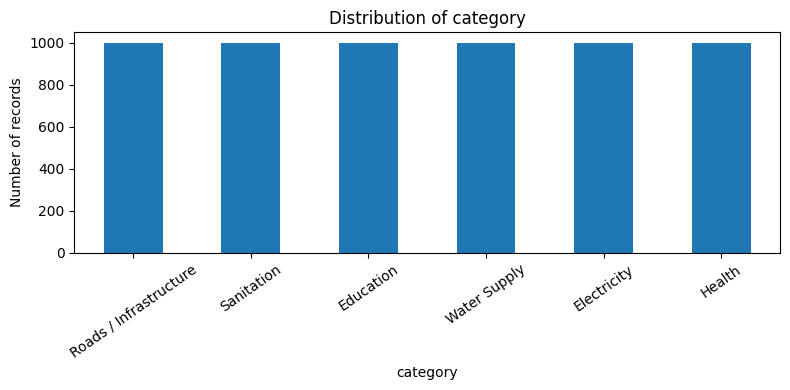

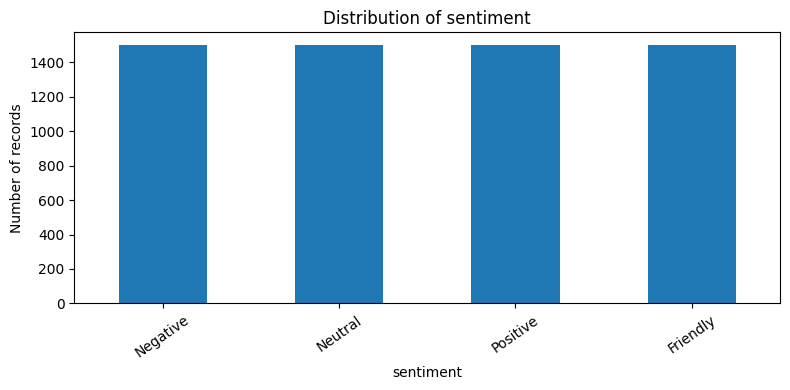

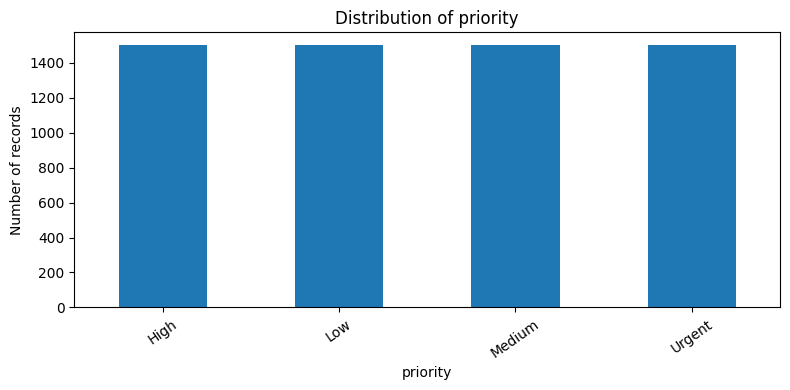

In [8]:
import matplotlib.pyplot as plt

for col in target_columns:
    df[col].value_counts().plot(
        kind="bar",
        figsize=(8, 4),
        title=f"Distribution of {col}"
    )

    plt.xlabel(col)
    plt.ylabel("Number of records")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

,text_length,word_count
count,6000.000000,6000.000000
mean,118.395000,23.254500
std,25.014628,5.021646
min,23.000000,4.000000
25%,103.000000,20.000000
50%,120.000000,24.000000
75%,136.000000,27.000000
max,186.000000,37.000000


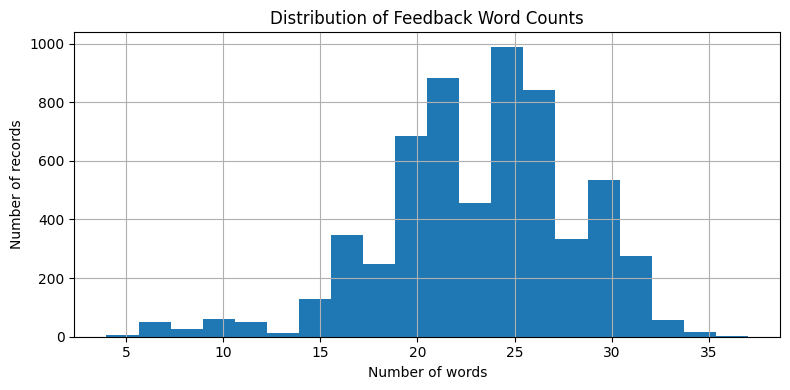

In [9]:
df["text_length"] = df["text"].astype(str).str.len()
df["word_count"] = df["text"].astype(str).str.split().str.len()

display(df[["text_length", "word_count"]].describe())

df["word_count"].hist(bins=20, figsize=(8, 4))
plt.title("Distribution of Feedback Word Counts")
plt.xlabel("Number of words")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

In [10]:
print("Labeling method distribution:")
display(df["label_method"].value_counts())

print("\nSource distribution:")
display(df["source"].value_counts())

print("\nSource vs labeling method:")
display(pd.crosstab(df["source"], df["label_method"]))

print("\nLabeling method vs sentiment:")
display(pd.crosstab(df["label_method"], df["sentiment"]))

print("\nLabeling method vs category:")
display(pd.crosstab(df["label_method"], df["category"]))

print("\nLabeling method vs priority:")
display(pd.crosstab(df["label_method"], df["priority"]))

Labeling method distribution:


label_method
rule_based      5742
hand_labeled     258
Name: count, dtype: int64


Source distribution:


source
template_synthetic    5742
seed_synthetic         258
Name: count, dtype: int64


Source vs labeling method:


...

sentiment,Friendly,Negative,Neutral,Positive
label_method,,,,
hand_labeled,48,170,22,18
rule_based,1452,1330,1478,1482



Labeling method vs category:


category,Education,Electricity,Health,Roads / Infrastructure,Sanitation,Water Supply
label_method,,,,,,
hand_labeled,43,43,43,43,43,43
rule_based,957,957,957,957,957,957



Labeling method vs priority:


priority,High,Low,Medium,Urgent
label_method,,,,
hand_labeled,66,70,67,55
rule_based,1434,1430,1433,1445


In [11]:
group_sizes = df.groupby("group_id").size()

print("Number of groups:", len(group_sizes))
print("Largest group size:", group_sizes.max())
print("Groups containing multiple records:", (group_sizes > 1).sum())

display(
    group_sizes
    .sort_values(ascending=False)
    .head(15)
    .rename("record_count")
    .to_frame()
)

Number of groups: 810
Largest group size: 20
Groups containing multiple records: 496


,record_count
group_id,
RD_R7,20
EL_R7,20
ED_R4,20
EL_R0,20
RD_R12,20
RD_R10,20
RD_R1,20
ED_R3,20
ED_R11,20


In [12]:
group_label_check = (
    df.groupby("group_id")
    .agg(
        records=("text", "size"),
        unique_categories=("category", "nunique"),
        unique_sentiments=("sentiment", "nunique"),
        unique_priorities=("priority", "nunique"),
    )
)

print("Groups with multiple labels:")

display(
    group_label_check[
        (group_label_check["unique_categories"] > 1)
        | (group_label_check["unique_sentiments"] > 1)
        | (group_label_check["unique_priorities"] > 1)
    ].sort_values("records", ascending=False)
)

print("\nTotal groups with inconsistent labels:", (
    (group_label_check["unique_categories"] > 1)
    | (group_label_check["unique_sentiments"] > 1)
    | (group_label_check["unique_priorities"] > 1)
).sum())

Groups with multiple labels:


,records,unique_categories,unique_sentiments,unique_priorities
group_id,,,,
RD_R1,20,1,1,2
HL_R0,20,1,1,2
WS_R9,20,1,1,2
WS_R4,20,1,1,2
SN_R1,20,1,1,2
...,...,...,...,...
HL_M3,4,1,3,1
HL_DL9,4,1,3,1
HL_DL1,4,1,3,1



Total groups with inconsistent labels: 462


In [13]:
print("Distribution of group sizes:")
display(
    df.groupby("group_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("records_per_group")
    .to_frame("number_of_groups")
)

Distribution of group sizes:


,number_of_groups
records_per_group,
1,314
2,34
4,10
5,22
6,26
7,46
8,58
9,40
10,25


In [14]:
print("Total rows:", len(df))
print("Unique group IDs:", df["group_id"].nunique())

group_sizes = df.groupby("group_id").size()

print("Groups by size:")
print(group_sizes.value_counts().sort_index())

print("Total records counted through groups:", group_sizes.sum())
print("Groups with multiple records:", (group_sizes > 1).sum())

group_label_check = df.groupby("group_id").agg(
    records=("text", "size"),
    categories=("category", "nunique"),
    sentiments=("sentiment", "nunique"),
    priorities=("priority", "nunique"),
)

print(
    "Groups with inconsistent target labels:",
    (
        (group_label_check["categories"] > 1)
        | (group_label_check["sentiments"] > 1)
        | (group_label_check["priorities"] > 1)
    ).sum()
)

Total rows: 6000
Unique group IDs: 810
Groups by size:
1     314
2      34
4      10
5      22
6      26
7      46
8      58
9      40
10     25
11      3
12      4
13      7
14     18
15     49
16     25
17     47
18     20
19     42
20     20
Name: count, dtype: int64
Total records counted through groups: 6000
Groups with multiple records: 496
Groups with inconsistent target labels: 462


In [15]:
# Find groups with inconsistent target labels
group_label_check = (
    df.groupby("group_id")
    .agg(
        records=("text", "size"),
        unique_categories=("category", "nunique"),
        unique_sentiments=("sentiment", "nunique"),
        unique_priorities=("priority", "nunique"),
    )
)

issue_groups = group_label_check[
    (group_label_check["unique_categories"] > 1)
    | (group_label_check["unique_sentiments"] > 1)
    | (group_label_check["unique_priorities"] > 1)
].index

print("Groups with inconsistent labels:", len(issue_groups))

Groups with inconsistent labels: 462


In [16]:
# Show every record belonging to an inconsistent group
issue_records = (
    df[df["group_id"].isin(issue_groups)]
    .sort_values(["group_id", "id"])
)

display(
    issue_records[
        [
            "id",
            "text",
            "category",
            "sentiment",
            "priority",
            "source",
            "label_method",
            "group_id",
        ]
    ]
)

,id,text,category,sentiment,priority,source,label_method,group_id
54,55,"Assalam o Alaikum, kal raat se school mein teachers aksar ghayab rehte hain. Allah aap ko jaza de, baqi tafseel aap ke pas mojood hai",Education,Friendly,High,template_synthetic,rule_based,ED_H0
2111,2112,"mohalla number 3 mn school mein teachers aksar ghayab rehte hain. kia koi helpline number he, baqi tafseel aap ke pas mojood he.",Education,Neutral,High,template_synthetic,rule_based,ED_H0
2269,2270,"hamari colony mn school me teachers aksar ghayab rehte hain, iska status kia hai, yeh sab ek hi ilaqe ky baat hy, pehle bhi is k zikr kiya ja chuk...",Education,Neutral,High,template_synthetic,rule_based,ED_H0
2904,2905,"School mein teachers aksar ghayab rehte hain! fori action lein, mohalle ke baqi log bhi yehi keh rahe hain",Education,Negative,High,template_synthetic,rule_based,ED_H0
3274,3275,"school mein teachers aksar ghayab rehte hain. jald az jald hal karein, baqi tafseel aap ke pas mojood hai, yeh sab ek hi ilaqe ki baat hai.",Education,Negative,High,template_synthetic,rule_based,ED_H0
...,...,...,...,...,...,...,...,...
4068,4069,"pani peene se ek bache ki maut ho gayi, is baray mein aap se rabta kiya hai.",Water Supply,Negative,Urgent,template_synthetic,rule_based,WS_U9
4620,4621,"hamare gaon mein pani peene sy ek bache ky maut ho gyi, iska status kia hai?",Water Supply,Neutral,Urgent,template_synthetic,rule_based,WS_U9
5034,5035,"Hamare ilaqe main kal raat se pani peene se ek bache ki maut ho gyi, iska status kia he, pehle bhi is k zikr kiya ja chuka hai.",Water Supply,Neutral,Urgent,template_synthetic,rule_based,WS_U9
5103,5104,"Assalam o Alaikum, pani peene se ek bache ky maut ho gayi. meharbani karke jldi madad karein. Allah aap ko jaza de, aas paas ke log bhi dekh rahe hn",Water Supply,Friendly,Urgent,template_synthetic,rule_based,WS_U9


In [17]:
priority_issue_groups = group_label_check[
    group_label_check["unique_priorities"] > 1
].index

priority_issues = (
    df[df["group_id"].isin(priority_issue_groups)]
    .sort_values(["group_id", "id"])
)

display(
    priority_issues[
        ["id", "text", "category", "sentiment", "priority", "group_id"]
    ]
)

,id,text,category,sentiment,priority,group_id
42,43,"shukriya, teachers aane lage hain, hum sab is baat par ittefaq karte hain, aas paas ke log bhi dekh rahe hain.",Education,Positive,Low,ED_R0
169,170,"bohat shukriya, teachers aane lage hain, bas ek classroom ki chat abhi bhi tapakti hai, pehle bhi is ka zikr kiya ja chuka hai, yeh ittila aap ko ...",Education,Positive,Medium,ED_R0
471,472,"bohat shukriya, teachers aane lage hain, is baray mein aap se rabta kiya hai, baqi tafseel aap ke pas mojood hai",Education,Positive,Low,ED_R0
686,687,"Teachers aane lage hain, acha kaam hua, par ek washroom abhi bhi band hai, aas paas ke log bhi dekh rahe hain, is baray mein aap se rabta kiya hai.",Education,Positive,Medium,ED_R0
1163,1164,"Bohat shukriya, teachers aane lage hain, hum sab is baat par ittefaq karte hain, yeh ittila aap ko dena zaroori tha",Education,Positive,Low,ED_R0
...,...,...,...,...,...,...
4411,4412,"Hamari colony mein nal ki marammat ho gayi hai, shukriya, lekin bill abhi tak durust nahi hua, aas paas ke log bhi dekh rahe hain.",Water Supply,Positive,Medium,WS_R9
4440,4441,"Shukriya, nal ki marammat ho gayi hai, magar bill abhi tak durust nahi hua, mohalle ke baqi log bhi yehi keh rahe hain.",Water Supply,Positive,Medium,WS_R9
4443,4444,"shukriya, nal ki marammat ho gayi hai, magar bill abhi tak durust nahi hua, is baray mein aap se rabta kiya hai, mohalle ke baqi log bhi yehi keh ...",Water Supply,Positive,Medium,WS_R9
4907,4908,"gali number 5 main nal ki marammat ho gayi hai, aap ki mehnat k shukriya, pehle bhi is ka zikr kiya ja chuka he.",Water Supply,Positive,Low,WS_R9


Import the required libraries

In [18]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

Create the three datasets

In [19]:
# Work on a copy; keep the original dataset unchanged
data = df.copy().reset_index(drop=True)

# Define text input, target label, and grouping information
X = data["text"]
y = data["category"]
groups = data["group_id"]

# First, reserve 15% of groups for testing
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split_1.split(X, y, groups=groups)
)

# Separate the remaining data into training and validation
remaining_data = data.iloc[train_val_idx].reset_index(drop=True)

split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(
    split_2.split(
        remaining_data["text"],
        remaining_data["category"],
        groups=remaining_data["group_id"]
    )
)

train_df = remaining_data.iloc[train_idx].copy()
val_df = remaining_data.iloc[val_idx].copy()
test_df = data.iloc[test_idx].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Train: 4137
Validation: 1007
Test: 856
Total: 6000


Verify the split

In [20]:
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

print("Train and validation overlap:", len(train_groups & val_groups))
print("Train and test overlap:", len(train_groups & test_groups))
print("Validation and test overlap:", len(val_groups & test_groups))

print("\nDataset proportions:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(part) / len(data):.2%}")

print("\nCategory distribution:")
print("Train:\n", train_df["category"].value_counts())
print("Validation:\n", val_df["category"].value_counts())
print("Test:\n", test_df["category"].value_counts())

Train and validation overlap: 0
Train and test overlap: 0
Validation and test overlap: 0

Dataset proportions:
Train: 68.95%
Validation: 16.78%
Test: 14.27%

Category distribution:
Train:
 category
Sanitation                798
Health                    681
Water Supply              680
Electricity               676
Roads / Infrastructure    664
Education                 638
Name: count, dtype: int64
Validation:
 category
Electricity               204
Roads / Infrastructure    195
Water Supply              191
Health                    177
Education                 167
Sanitation                 73
Name: count, dtype: int64
Test:
 category
Education                 195
Health                    142
Roads / Infrastructure    141
Sanitation                129
Water Supply              129
Electricity               120
Name: count, dtype: int64


In [21]:
from pathlib import Path

output_dir = Path(
    r"E:\CitizenSense Sentiment Project\data\processed"
)

# Create the folder if it doesn't exist
output_dir.mkdir(parents=True, exist_ok=True)

# Save the three splits
train_df.to_csv(output_dir / "train.csv", index=False)
val_df.to_csv(output_dir / "validation.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

print("Saved files:")
for file in sorted(output_dir.glob("*.csv")):
    print(file, "|", pd.read_csv(file).shape)

Saved files:
E:\CitizenSense Sentiment Project\data\processed\test.csv | (856, 10)
E:\CitizenSense Sentiment Project\data\processed\train.csv | (4137, 10)
E:\CitizenSense Sentiment Project\data\processed\validation.csv | (1007, 10)


Import libraries

In [22]:
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Define project paths

In [23]:
PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for folder in [PROCESSED_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Models directory:", MODELS_DIR)
print("Reports directory:", REPORTS_DIR)

Project directory: E:\CitizenSense Sentiment Project
Processed data directory: E:\CitizenSense Sentiment Project\data\processed
Models directory: E:\CitizenSense Sentiment Project\models
Reports directory: E:\CitizenSense Sentiment Project\reports


Load the saved dataset splits

In [24]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (4137, 10)
Validation shape: (1007, 10)
Testing shape: (856, 10)


Validate the datasets

In [25]:
required_columns = {"text", "category", "sentiment", "priority", "group_id"}

for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing_columns = required_columns - set(frame.columns)

    if missing_columns:
        raise ValueError(f"{name} is missing columns: {missing_columns}")

    if frame["text"].isna().any():
        raise ValueError(f"{name} contains missing text.")

    if frame["category"].isna().any():
        raise ValueError(f"{name} contains missing categories.")

    if frame["text"].astype(str).str.strip().eq("").any():
        raise ValueError(f"{name} contains empty text.")

    print(f"{name}: validation passed.")

# Check for group leakage
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert not (train_groups & val_groups), "Train/validation group leakage!"
assert not (train_groups & test_groups), "Train/test group leakage!"
assert not (val_groups & test_groups), "Validation/test group leakage!"

print("No group overlap found.")

Train: validation passed.
Validation: validation passed.
Test: validation passed.
No group overlap found.


Prepare the training, validation, and test data

In [26]:
# Input features
X_train = train_df["text"].astype(str)
X_val = val_df["text"].astype(str)
X_test = test_df["text"].astype(str)

# Target labels
y_train = train_df["category"].astype(str)
y_val = val_df["category"].astype(str)
y_test = test_df["category"].astype(str)

# Verify that validation and test categories exist in training data
assert set(y_val.unique()).issubset(set(y_train.unique()))
assert set(y_test.unique()).issubset(set(y_train.unique()))

print("Data preparation completed.")
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples: {len(X_test)}")
print(f"Number of categories: {y_train.nunique()}")

print("\nTraining category distribution:")
print(y_train.value_counts())

Data preparation completed.
Training samples: 4137
Validation samples: 1007
Test samples: 856
Number of categories: 6

Training category distribution:
category
Sanitation                798
Health                    681
Water Supply              680
Electricity               676
Roads / Infrastructure    664
Education                 638
Name: count, dtype: int64


Import model libraries

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd
import json
import joblib
from pathlib import Path

Configure project paths

In [28]:
PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for folder in [MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output directories are ready.")

Output directories are ready.


Build the baseline model

In [29]:
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=20000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("TF-IDF + Logistic Regression model created.")

TF-IDF + Logistic Regression model created.


Train the model

In [30]:
baseline_model.fit(X_train, y_train)

print("Training completed successfully.")

print(
    "Number of TF-IDF features:",
    len(baseline_model.named_steps["tfidf"].vocabulary_)
)

Training completed successfully.
Number of TF-IDF features: 7798


Evaluate on the validation set

In [31]:
val_predictions = baseline_model.predict(X_val)

val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print("\nValidation Classification Report:")

print(
    classification_report(
        y_val,
        val_predictions,
        zero_division=0
    )
)

Validation Accuracy: 0.8431

Validation Classification Report:
                        precision    recall  f1-score   support

             Education       0.90      0.83      0.86       167
           Electricity       0.80      0.79      0.80       204
                Health       0.87      0.86      0.87       177
Roads / Infrastructure       0.87      0.84      0.85       195
            Sanitation       0.76      0.97      0.85        73
          Water Supply       0.84      0.85      0.84       191

              accuracy                           0.84      1007
             macro avg       0.84      0.86      0.85      1007
          weighted avg       0.85      0.84      0.84      1007



Save validation metrics

In [32]:
val_report = classification_report(
    y_val,
    val_predictions,
    output_dict=True,
    zero_division=0
)

validation_metrics = {
    "task": "category_classification",
    "model": "TF-IDF + Logistic Regression",
    "validation_samples": int(len(y_val)),
    "accuracy": float(val_accuracy),
    "macro_precision": float(val_report["macro avg"]["precision"]),
    "macro_recall": float(val_report["macro avg"]["recall"]),
    "macro_f1": float(val_report["macro avg"]["f1-score"]),
    "weighted_f1": float(val_report["weighted avg"]["f1-score"])
}

with open(
    REPORTS_DIR / "baseline_validation_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(validation_metrics, file, indent=4)

print("Validation metrics saved.")

Validation metrics saved.


Plot the confusion matrix

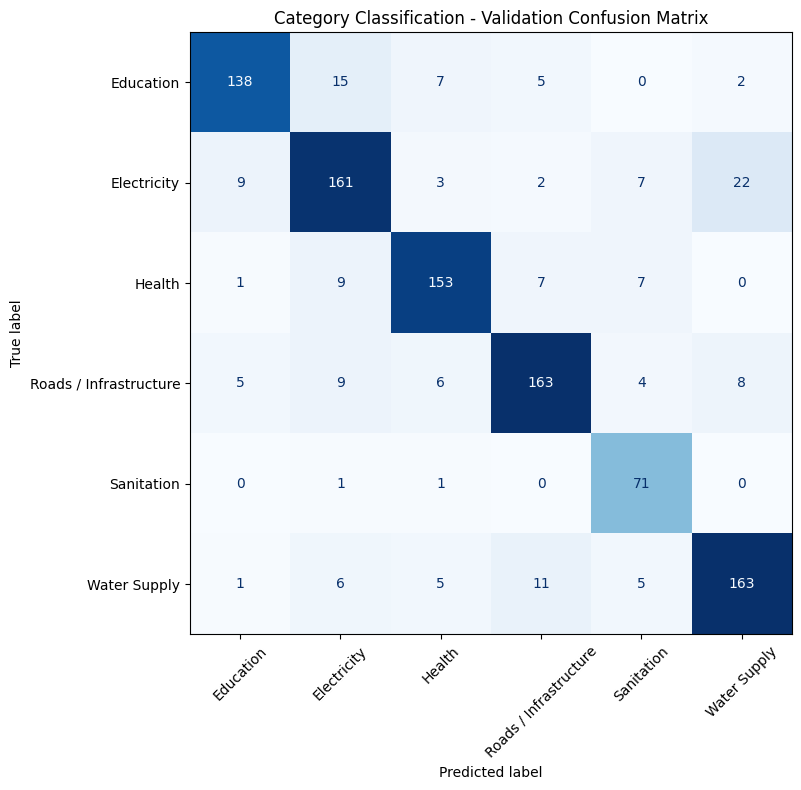

In [33]:
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=baseline_model.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

ax.set_title("Category Classification - Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_validation_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Inspect incorrect predictions

In [34]:
misclassified = val_df[
    ["text", "category", "group_id"]
].copy()

misclassified["predicted_category"] = val_predictions

misclassified["correct"] = (
    misclassified["category"]
    == misclassified["predicted_category"]
)

errors = misclassified[
    ~misclassified["correct"]
].copy()

errors.to_csv(
    REPORTS_DIR / "baseline_validation_errors.csv",
    index=False
)

print("Total incorrect validation predictions:", len(errors))

display(errors.head(15))

Total incorrect validation predictions: 158


,text,category,group_id,predicted_category,correct
3,"bohat shukriyah, bjli k masla hal ho gaya hy, mohalle ke baqi lug bhi yehi keh rahe hein, aas paas ke lug bhi dekh rahe hein.",Electricity,EL_R10,Health,False
33,"hospital ke qareeb pany ky supply bnd hai or mariz pareshan hein, boht shukriya, baqi tafseel aap ke pas mojood hai, mohalle ke baqi lug bhi yehi ...",Water Supply,WS_U3,Health,False
34,"hamare ilaqe mein free uniform mil gaya. bohat acha kaam kiya, is baray mein aap se rabta kiya hai, yeh sab ek hi ilaqe ki baat hai",Education,ED_R6,Health,False
42,hamari colony mein yeh masla hai ke bus stop ka shed purana ho gaya hai. is ka koi khayal nahi kar raha.,Roads / Infrastructure,RD_L6,Water Supply,False
47,"bohat shukriya, machine theek ho gayi hai, baqi tafseel aap ke pas mojood hai, mohalle ke baqi log bhi yehi keh rahe hain, pehle bhi is ka zikr ki...",Health,HL_R8,Electricity,False
55,"behtareen kaam, hamrai colony mein aap ki team ne hospital ka masla hal kar diya hai",Health,HL_R11,Roads / Infrastructure,False
58,"sarak par bijli ke khambe ke ird gird gaddha ban gaya hai, pichle kuch dinon se yeh jaari hai. koi sunne wala nahi.",Roads / Infrastructure,RD_H9,Electricity,False
62,"Hamare sector mein sarak par bijli ke khambe ke ird gird gaddha ban gaya hai, kis department ko batana chahiye, is baray mein aap se rabta kiya hai.",Roads / Infrastructure,RD_H9,Electricity,False
81,gali number 5 mein kal raat se nal se mitti mila pani aa raha hai. koi sunne wala nahi,Water Supply,WS_H11,Sanitation,False
91,"school mein bijli ka khula taar hai aur bache haath laga rahe hain, kya is ki ittila pehle di ja chuki hai, aas paas ke log bhi dekh rahe hain.",Education,ED_U15,Electricity,False


Test predictions on new examples

In [35]:
sample_feedback = [
    "Pani ki supply teen din se band hai.",
    "Hamari gali ki road toot chuki hai.",
    "Area mein kachra jama ho raha hai.",
    "Bijli bar bar band ho rahi hai."
]

sample_predictions = baseline_model.predict(sample_feedback)

for feedback, prediction in zip(
    sample_feedback,
    sample_predictions
):
    print("Feedback:", feedback)
    print("Predicted category:", prediction)
    print("-" * 50)

Feedback: Pani ki supply teen din se band hai.
Predicted category: Water Supply
--------------------------------------------------
Feedback: Hamari gali ki road toot chuki hai.
Predicted category: Roads / Infrastructure
--------------------------------------------------
Feedback: Area mein kachra jama ho raha hai.
Predicted category: Sanitation
--------------------------------------------------
Feedback: Bijli bar bar band ho rahi hai.
Predicted category: Electricity
--------------------------------------------------


Check the category model's validation performance

In [36]:
from sklearn.metrics import classification_report
import pandas as pd

val_predictions = baseline_model.predict(X_val)

category_report = classification_report(
    y_val,
    val_predictions,
    output_dict=True,
    zero_division=0
)

category_metrics = pd.DataFrame(category_report).T

display(
    category_metrics[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

,precision,recall,f1-score,support
Education,0.896,0.826,0.860,167.000
Electricity,0.801,0.789,0.795,204.000
Health,0.874,0.864,0.869,177.000
Roads / Infrastructure,0.867,0.836,0.851,195.000
Sanitation,0.755,0.973,0.850,73.000
Water Supply,0.836,0.853,0.845,191.000
accuracy,0.843,0.843,0.843,0.843
macro avg,0.838,0.857,0.845,1007.000
weighted avg,0.846,0.843,0.843,1007.000


Run the final test evaluation

In [37]:
from sklearn.metrics import accuracy_score, classification_report

test_predictions = baseline_model.predict(X_test)

print("Test Accuracy:", round(
    accuracy_score(y_test, test_predictions) * 100, 2
), "%")

print("\nTest Classification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

Test Accuracy: 85.86 %

Test Classification Report:
                        precision    recall  f1-score   support

             Education       0.90      0.93      0.91       195
           Electricity       0.84      0.85      0.84       120
                Health       0.86      0.98      0.92       142
Roads / Infrastructure       0.95      0.87      0.91       141
            Sanitation       0.92      0.69      0.79       129
          Water Supply       0.69      0.79      0.74       129

              accuracy                           0.86       856
             macro avg       0.86      0.85      0.85       856
          weighted avg       0.87      0.86      0.86       856



Save the final category model

In [38]:
import joblib

model_path = MODELS_DIR / "tfidf_logistic_regression.joblib"

joblib.dump(baseline_model, model_path)

print("Saved category model:", model_path)

Saved category model: E:\CitizenSense Sentiment Project\models\tfidf_logistic_regression.joblib


Start the sentiment classifier

In [39]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for folder in [MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nSentiment labels in training data:")
print(train_df["sentiment"].value_counts(dropna=False))

Training: (4137, 10)
Validation: (1007, 10)
Test: (856, 10)

Sentiment labels in training data:
sentiment
Positive    1070
Negative    1031
Neutral     1021
Friendly    1015
Name: count, dtype: int64


Validate sentiment labels

In [40]:
required_columns = {"text", "sentiment", "group_id"}

for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

    if frame["sentiment"].isna().any():
        raise ValueError(f"{name} contains missing sentiment labels.")

    if frame["text"].isna().any():
        raise ValueError(f"{name} contains missing text.")

    print(f"{name} validation passed.")

print("\nTraining sentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nValidation sentiment distribution:")
print(val_df["sentiment"].value_counts())

print("\nTest sentiment distribution:")
print(test_df["sentiment"].value_counts())

Train validation passed.
Validation validation passed.
Test validation passed.

Training sentiment distribution:
sentiment
Positive    1070
Negative    1031
Neutral     1021
Friendly    1015
Name: count, dtype: int64

Validation sentiment distribution:
sentiment
Neutral     274
Friendly    271
Negative    244
Positive    218
Name: count, dtype: int64

Test sentiment distribution:
sentiment
Negative    225
Friendly    214
Positive    212
Neutral     205
Name: count, dtype: int64


Check for group leakage

In [41]:
train_groups = set(train_df["group_id"].dropna())
val_groups = set(val_df["group_id"].dropna())
test_groups = set(test_df["group_id"].dropna())

assert train_groups.isdisjoint(val_groups), "Train/validation leakage!"
assert train_groups.isdisjoint(test_groups), "Train/test leakage!"
assert val_groups.isdisjoint(test_groups), "Validation/test leakage!"

print("No group overlap found.")

No group overlap found.


Prepare the text and target labels

In [42]:
X_train = train_df["text"].astype(str)
y_train = train_df["sentiment"].astype(str)

X_val = val_df["text"].astype(str)
y_val = val_df["sentiment"].astype(str)

X_test = test_df["text"].astype(str)
y_test = test_df["sentiment"].astype(str)

assert set(y_val.unique()).issubset(set(y_train.unique()))
assert set(y_test.unique()).issubset(set(y_train.unique()))

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("Sentiment classes:", sorted(y_train.unique()))

Training samples: 4137
Validation samples: 1007
Test samples: 856
Sentiment classes: ['Friendly', 'Negative', 'Neutral', 'Positive']


Build the sentiment classifier

In [43]:
sentiment_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=20000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Sentiment classifier created.")

Sentiment classifier created.


Train the model

In [44]:
sentiment_model.fit(X_train, y_train)

print("Sentiment model training completed.")
print(
    "TF-IDF features learned:",
    len(sentiment_model.named_steps["tfidf"].vocabulary_)
)

Sentiment model training completed.
TF-IDF features learned: 7798


Evaluate on validation data

In [45]:
val_predictions = sentiment_model.predict(X_val)

val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Validation accuracy: {val_accuracy:.4f}")

print("\nValidation classification report:")

print(
    classification_report(
        y_val,
        val_predictions,
        zero_division=0
    )
)

Validation accuracy: 0.9861

Validation classification report:
              precision    recall  f1-score   support

    Friendly       1.00      0.99      0.99       271
    Negative       0.97      0.98      0.98       244
     Neutral       1.00      0.98      0.99       274
    Positive       0.97      0.99      0.98       218

    accuracy                           0.99      1007
   macro avg       0.99      0.99      0.99      1007
weighted avg       0.99      0.99      0.99      1007



Plot the confusion matrix

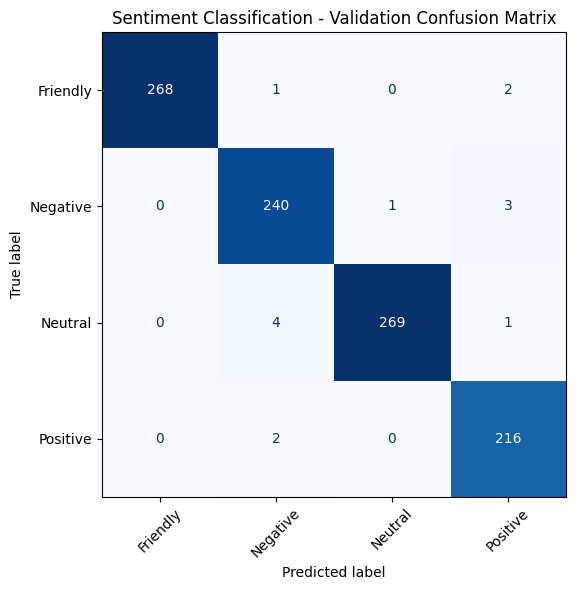

In [46]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=sentiment_model.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

ax.set_title("Sentiment Classification - Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "sentiment_validation_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Save validation metrics

In [47]:
val_report = classification_report(
    y_val,
    val_predictions,
    output_dict=True,
    zero_division=0
)

validation_metrics = {
    "task": "sentiment_classification",
    "model": "TF-IDF + Logistic Regression",
    "validation_samples": int(len(y_val)),
    "accuracy": float(val_accuracy),
    "macro_precision": float(val_report["macro avg"]["precision"]),
    "macro_recall": float(val_report["macro avg"]["recall"]),
    "macro_f1": float(val_report["macro avg"]["f1-score"]),
    "weighted_f1": float(val_report["weighted avg"]["f1-score"])
}

with open(
    REPORTS_DIR / "sentiment_validation_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(validation_metrics, file, indent=4)

print("Sentiment validation metrics saved.")

Sentiment validation metrics saved.


Save the sentiment model

In [48]:
sentiment_model_path = MODELS_DIR / "tfidf_sentiment_classifier.joblib"

joblib.dump(sentiment_model, sentiment_model_path)

print("Sentiment model saved to:", sentiment_model_path)

Sentiment model saved to: E:\CitizenSense Sentiment Project\models\tfidf_sentiment_classifier.joblib


Test sample feedback

In [49]:
sample_feedback = [
    "Bohat achi service hai, shukriya.",
    "Hamari complaint abhi tak solve nahi hui.",
    "Application kal submit ki thi."
]

sample_predictions = sentiment_model.predict(sample_feedback)

for feedback, prediction in zip(sample_feedback, sample_predictions):
    print("Feedback:", feedback)
    print("Predicted sentiment:", prediction)
    print("-" * 50)

Feedback: Bohat achi service hai, shukriya.
Predicted sentiment: Positive
--------------------------------------------------
Feedback: Hamari complaint abhi tak solve nahi hui.
Predicted sentiment: Negative
--------------------------------------------------
Feedback: Application kal submit ki thi.
Predicted sentiment: Neutral
--------------------------------------------------


Final test evaluation

In [50]:
test_predictions = sentiment_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Sentiment test accuracy: {test_accuracy:.4f}")

print("\nFinal test classification report:")

print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

Sentiment test accuracy: 0.9825

Final test classification report:
              precision    recall  f1-score   support

    Friendly       1.00      0.97      0.99       214
    Negative       0.95      1.00      0.97       225
     Neutral       1.00      0.97      0.98       205
    Positive       0.99      1.00      0.99       212

    accuracy                           0.98       856
   macro avg       0.98      0.98      0.98       856
weighted avg       0.98      0.98      0.98       856



Priority notebook mein data load aur verify karo

In [51]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nAvailable columns:")
print(train_df.columns.tolist())

print("\nPriority distribution in training data:")
print(train_df["priority"].value_counts(dropna=False))

print("\nPriority distribution in validation data:")
print(val_df["priority"].value_counts(dropna=False))

print("\nPriority distribution in test data:")
print(test_df["priority"].value_counts(dropna=False))

print("\nMissing priority labels:")
print({
    "train": train_df["priority"].isna().sum(),
    "validation": val_df["priority"].isna().sum(),
    "test": test_df["priority"].isna().sum()
})


Train shape: (4137, 10)
Validation shape: (1007, 10)
Test shape: (856, 10)

Available columns:
['id', 'text', 'category', 'sentiment', 'priority', 'source', 'label_method', 'group_id', 'text_length', 'word_count']

Priority distribution in training data:
priority
Low       1086
High      1053
Medium    1029
Urgent     969
Name: count, dtype: int64

Priority distribution in validation data:
priority
Medium    282
High      281
Urgent    247
Low       197
Name: count, dtype: int64

Priority distribution in test data:
priority
Urgent    284
Low       217
Medium    189
High      166
Name: count, dtype: int64

Missing priority labels:
{'train': np.int64(0), 'validation': np.int64(0), 'test': np.int64(0)}


Test distribution check karo

In [52]:

print("Test priority distribution:")
print(
    test_df["priority"]
    .value_counts(dropna=False)
    .reindex(["Low", "Medium", "High", "Urgent"], fill_value=0)
)


Test priority distribution:
priority
Low       217
Medium    189
High      166
Urgent    284
Name: count, dtype: int64


priority model train

In [53]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

# Check that the required fields are available
for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    assert df["text"].notna().all(), f"Missing text in {name}"
    assert df["priority"].notna().all(), f"Missing priority in {name}"

# Use only complaint text to predict priority
X_train = train_df["text"].astype(str)
y_train = train_df["priority"].astype(str)

X_val = val_df["text"].astype(str)
y_val = val_df["priority"].astype(str)

priority_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=20000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Train the model
priority_model.fit(X_train, y_train)

# Evaluate on validation data
val_predictions = priority_model.predict(X_val)

print("Priority Validation Accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))

print("\nValidation Classification Report:\n")
print(classification_report(
    y_val,
    val_predictions,
    labels=["Low", "Medium", "High", "Urgent"],
    zero_division=0
))


Priority Validation Accuracy: 0.6018

Validation Classification Report:

              precision    recall  f1-score   support

         Low       0.56      0.88      0.69       197
      Medium       0.71      0.49      0.58       282
        High       0.51      0.51      0.51       281
      Urgent       0.68      0.62      0.65       247

    accuracy                           0.60      1007
   macro avg       0.62      0.62      0.60      1007
weighted avg       0.62      0.60      0.60      1007



Validation confusion matrix banao

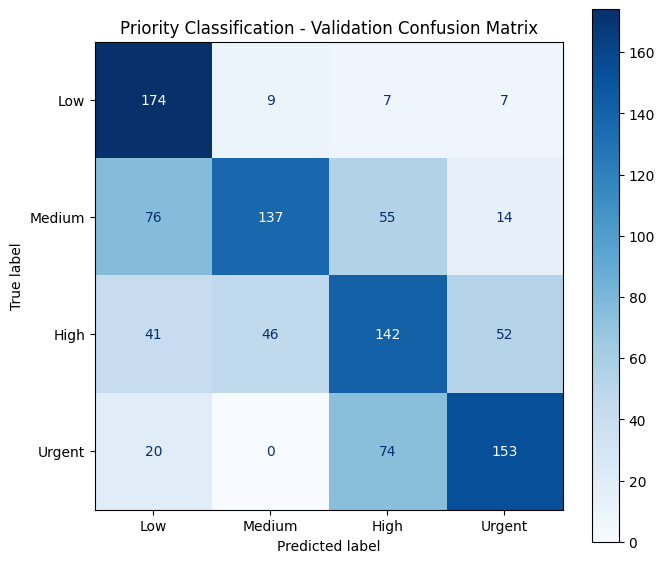

In [54]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

priority_labels = ["Low", "Medium", "High", "Urgent"]

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=priority_labels
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=priority_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Priority Classification - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


Validation errors dekho

In [55]:

validation_errors = val_df[
    ["text", "priority"]
].copy()

validation_errors["predicted_priority"] = val_predictions

validation_errors = validation_errors[
    validation_errors["priority"]
    != validation_errors["predicted_priority"]
]

print("Total validation errors:", len(validation_errors))
display(validation_errors.reset_index(drop=True))


Total validation errors: 401


,text,priority,predicted_priority
0,"hamari gali mein yeh masla hai ke bill adaa karne ke bawajood connection kaat diya gaya. hum tang aa chuke hain, yeh ittila aap ko dena zaroori tha.",High,Low
1,"masjid ke saamne high voltage sy tv aor fridge jal gaye, ye shikayat kahan darj karwani hy, baqi tafseel aap ke pas mojood hai",High,Urgent
2,"kai mahino se pani ka rang halka peela hai, is ka koi khayal nahi kar raha, aas paas ke log bhi dekh rahe hain.",Medium,Low
3,hamare area mein yeh masla hai ke bijli roz raat ko 2 ghante jaati hai. log bohat naraz hain.,Medium,High
4,"kia aap bata sakte hain ke mohalla number 3 me emergency mein daktar ne ilaj sy inkar kar diya, to kis sy rabta karun?",Urgent,High
...,...,...,...
396,"Dear sir, bazaar ke qareeb mahine se skool main furniture nahi hai. aap ka bohat shukriya, yeh sab ek hi liaqe ky baat he.",Medium,High
397,"Aadab, hospital k washroom bahut ganda hai. aap k ehsan hoga agar yeh masla hal ho jaye, aap k waqt dene k shukriya.",Medium,High
398,yeh masla hai ke sarak kai mahino se tooti hui hai aur rickshaw palat jate hain. kab tak aisa chalega,High,Urgent
399,"Hello sir, pani mein halki si badbu hai. Allah aap ko jaza de, is baray mein aap se rabta kiya hai.",Medium,Low


In [56]:

# Inspect examples for each priority in the training data

for label in ["Low", "Medium", "High", "Urgent"]:
    print(f"\n{'=' * 20} {label} {'=' * 20}")

    examples = train_df.loc[
        train_df["priority"] == label, "text"
    ].head(10)

    for i, text in enumerate(examples, start=1):
        print(f"{i}. {text}")



==================== Low ====================
1. behtareen kaam, hamare sector mein scholarship mil gayi hai, yeh sab ek hi ilaqe ki baat hai, yeh ittila aap ko dena zaroori tha, pehle bhi is ka zikr kiya ja chuka hai
2. Dutsbin ka rang utar gaya hai. ye sab bohat ghalat hai, pehle bhi is ka zikr kiya ja chuka hai.
3. Hello sir, mujhe ye batana tha ke hamari colony mein footpath ki tiles tooti hui hain. aap ka bohat shukriya, mohalle ke baqi log bhi yehi keh rahe hain
4. Kia aap bata sakte hein ke hamare sector mein hospital mein pankhon ky awaaz bohat he, to kis se rabta karun, yeh ittila aap ko dena zaroori tha.
5. Assalam o Alaikum, mujhe ye batana tha ke hamare mohalle mein park mein thora kachra bikhra pada hai. aap ka waqt dene ka shukriya.
6. Filtration plant chal gya he. bohat acha kaam kiya, is baray mn aap se rabta kiya hy, pehle bhi is ka zikr kiya ja chuka hai.
7. behtareen kaam, hamari gali mein nalay ki marammat ho gayi hai, yeh ittila aap ko dena zaroori tha
8. shukriya

In [57]:

ERRORS_PATH = PROJECT_DIR / "reports" / "priority_validation_errors.csv"
ERRORS_PATH.parent.mkdir(parents=True, exist_ok=True)

validation_errors.to_csv(ERRORS_PATH, index=False)

print("Validation errors saved to:")
print(ERRORS_PATH)
print("Total errors:", len(validation_errors))


Validation errors saved to:
E:\CitizenSense Sentiment Project\reports\priority_validation_errors.csv
Total errors: 401


In [58]:

for label in ["Low", "Medium", "High", "Urgent"]:
    print(f"\n{'=' * 15} {label} {'=' * 15}")

    examples = train_df.loc[
        train_df["priority"] == label,
        ["text", "category", "sentiment", "priority"]
    ].sample(
        n=min(5, (train_df["priority"] == label).sum()),
        random_state=42
    )

    for _, row in examples.iterrows():
        print(f"\nText: {row['text']}")
        print(f"Category: {row['category']}")
        print(f"Sentiment: {row['sentiment']}")
        print(f"Priority: {row['priority']}")



=============== Low ===============

Text: Ab bill durust kar diya gaya hai, hum aap ke mashkoor hain, baqi tafseel aap ke pas mojood hai, aas paas ke log bhi dekh rahe hain.
Category: Electricity
Sentiment: Positive
Priority: Low

Text: behtareen kaam, hamare gaon mein test ki report waqt par mil gayi, pehle bhi is ka zikr kiya ja chuka hai.
Category: Health
Sentiment: Positive
Priority: Low

Text: block B mein hafte se school ki ghanti kharb hy. aaj subah se yeh masla hai, baqi tafseel aap ke pas mojood hy.
Category: Education
Sentiment: Negative
Priority: Low

Text: sir, kachra uthane ka waqt kya hai, is baray main aap sy rabta kiya hy, aas paas ke lug bhi dekh rahe hein, pehle bhi is ka zikr kiya ja chuka hy.
Category: Sanitation
Sentiment: Neutral
Priority: Low

Text: bijli ke dabbe par naam ka board nahi hai, is ki complaint ka tracking number kahan se milega, is baray mein aap se rabta kiya hai.
Category: Electricity
Sentiment: Neutral
Priority: Low

=============== Medium ====

In [59]:

print("Priority counts by category:\n")

print(pd.crosstab(
    train_df["category"],
    train_df["priority"],
    margins=True
))

print("\nPriority counts by sentiment:\n")

print(pd.crosstab(
    train_df["sentiment"],
    train_df["priority"],
    margins=True
))


Priority counts by category:

priority                High   Low  Medium  Urgent   All
category                                                
Education                178   170     180     110   638
Electricity              127   189     200     160   676
Health                   200   191     161     129   681
Roads / Infrastructure   171   163     149     181   664
Sanitation               214   186     181     217   798
Water Supply             163   187     158     172   680
All                     1053  1086    1029     969  4137

Priority counts by sentiment:

priority   High   Low  Medium  Urgent   All
sentiment                                  
Friendly    353   181     160     321  1015
Negative    349   190     172     320  1031
Neutral     351   181     161     328  1021
Positive      0   534     536       0  1070
All        1053  1086    1029     969  4137


In [60]:

priority_by_sentiment = pd.crosstab(
    train_df["sentiment"],
    train_df["priority"],
    normalize="index"
).mul(100).round(1)

print("Priority percentage within each sentiment:\n")
print(priority_by_sentiment)

priority_by_sentiment = pd.crosstab(
    train_df["sentiment"],
    train_df["priority"],
    normalize="index"
).mul(100).round(1)

print("Priority percentage within each sentiment:\n")
print(priority_by_sentiment)


Priority percentage within each sentiment:

priority   High   Low  Medium  Urgent
sentiment                            
Friendly   34.8  17.8    15.8    31.6
Negative   33.9  18.4    16.7    31.0
Neutral    34.4  17.7    15.8    32.1
Positive    0.0  49.9    50.1     0.0
Priority percentage within each sentiment:

priority   High   Low  Medium  Urgent
sentiment                            
Friendly   34.8  17.8    15.8    31.6
Negative   33.9  18.4    16.7    31.0
Neutral    34.4  17.7    15.8    32.1
Positive    0.0  49.9    50.1     0.0


In [61]:

for label in ["Low", "Medium", "High", "Urgent"]:
    subset = train_df[train_df["priority"] == label]

    print(f"\n{'=' * 15} {label} {'=' * 15}")

    sample = subset.sample(
        n=min(10, len(subset)),
        random_state=42
    )

    display(
        sample[["text", "category", "sentiment", "priority"]]
        .reset_index(drop=True)
    )



=============== Low ===============


,text,category,sentiment,priority
0,"Ab bill durust kar diya gaya hai, hum aap ke mashkoor hain, baqi tafseel aap ke pas mojood hai, aas paas ke log bhi dekh rahe hain.",Electricity,Positive,Low
1,"behtareen kaam, hamare gaon mein test ki report waqt par mil gayi, pehle bhi is ka zikr kiya ja chuka hai.",Health,Positive,Low
2,"block B mein hafte se school ki ghanti kharb hy. aaj subah se yeh masla hai, baqi tafseel aap ke pas mojood hy.",Education,Negative,Low
3,"sir, kachra uthane ka waqt kya hai, is baray main aap sy rabta kiya hy, aas paas ke lug bhi dekh rahe hein, pehle bhi is ka zikr kiya ja chuka hy.",Sanitation,Neutral,Low
4,"bijli ke dabbe par naam ka board nahi hai, is ki complaint ka tracking number kahan se milega, is baray mein aap se rabta kiya hai.",Electricity,Neutral,Low
5,"block B mein speed breaker tehek kar diye gaye hain. bohat acha kaam kiya, hum sab is baat par ittefaq karte hain.",Roads / Infrastructure,Positive,Low
6,"Speed breaker theek kar diye gaye hain, shukriya, pehle bhi is ka zikr kiya ja chuka hai, aas paas ke log bhi dekh rahe hain",Roads / Infrastructure,Positive,Low
7,"behtareen kaam, hamare gaon mein scholarship mil gayi hai, is baray mein aap se rabta kiya hai, pehle bhi is ka zikr kiya ja chuka hai.",Education,Positive,Low
8,"yeh masla hai ke safai ka ittila board nahi hai. bohat pareshani hai, hum sab is baat par ittefaq karte hain.",Sanitation,Negative,Low
9,"shukriya, gaddhe bhar diye gaye hain, is baray mein aap se rabta kiya hai, hum sab is baat par ittefaq karte hain.",Roads / Infrastructure,Positive,Low



=============== Medium ===============


,text,category,sentiment,priority
0,"bohat shukriya, naya meter lag gaya hai, bas street light ka kaam abhi baqi hai, hum sab is baat par ittefaq karte hain.",Electricity,Positive,Medium
1,"Hamari gali mein yeh masla hai ke meter ki reading galat aayi hai. ye bilkul bardasht nahi, yeh ittila aap ko dena zaroori tha",Electricity,Negative,Medium
2,"bill durust kar diya gaya hy, acha kaam hua, par doosre mohalle mein abhi bhi load shedding hai, yeh sab ek hi ilaqe ky baat he.",Electricity,Positive,Medium
3,"Filtration plant chal gaya hai, acha kaam hua, par ek pipe abhi bhi leak ho rahi hai",Water Supply,Positive,Medium
4,"shukria, aap ky team ne bijli ka masla hal kar diya hy, magar bill abhi tak druust nahi hua, pehle bhi is k zikr kiya ja chuka hai.",Electricity,Positive,Medium
5,"hamare area main nale ki safai nahi hui, is par kb tak amal hoga, is baray me aap se rabta kiya hy, baqi tafseel aap ke pas mojood hai.",Sanitation,Neutral,Medium
6,"hamare gaon mn sarak k masla hal ho gaya he, shukriyah, lekin line markings abhi adhuri hn.",Roads / Infrastructure,Positive,Medium
7,"hamari colony mein baarish ka pani sarak par kai ghante jama rehta hai. jald az jald hal karein, yeh ittila aap ko dena zaroori tha.",Roads / Infrastructure,Negative,Medium
8,"hamare mohalle mein kai mahino se school transport ki gari kharab hai, ye sab bohat ghalat hai",Education,Negative,Medium
9,"Janab-e-aali, mujhe ye batana tha ke hamare sector mein gali mein kachra phenk diya jata hai aur koi nigrani nahi. Allah aap ko jaza de.",Sanitation,Friendly,Medium



=============== High ===============


,text,category,sentiment,priority
0,"salam, bijli ke taar darakhton se lag rahi hain. aap ki madad ka intezar rahega. allah aap ko jaza de, yeh ittila aap ko dena zaroori tha.",Electricity,Friendly,High
1,"water filtration plant band hai, kya is ki ittila pehle di ja chuki hai, baqi tafseel aap ke pas mojood hai, yeh ittila aap ko dena zaroori tha.",Water Supply,Neutral,High
2,"Sarak par tel girne se phisalan hai aur kayi log gir chuke hain, kai mahino se yehi haal hai. ye bilkul bardasht nahi, pehle bhi is ka zikr kiya j...",Roads / Infrastructure,Negative,High
3,"Tube well kharab hai aur poore mohalle mein pani band hai hamare sector mein, yeh ittila aap ko dena zaroori tha",Water Supply,Negative,High
4,"Ek bachay ko TB ki bimari hai aur dawai mehngi hai, kis department ko batana chahiye, hum sab is baat par ittefaq karte hain.",Health,Neutral,High
5,"tanker bohat mehnga hai aur ghareeb log pareshan hain! jald az jald hal karein, is baray mein aap se rabta kiya hai, aas paas ke log bhi dekh rahe...",Water Supply,Negative,High
6,"Gali number 5 main skool mein sirf 2 teachers hain aor 300 bache, kis department ko batana chahiye",Education,Neutral,High
7,"School ke samne traffic k ghalat nizam hy or bache khatre mein hain, is ki complaint ka tracking number kahan se milega?",Roads / Infrastructure,Neutral,High
8,"Principal parhai ke baghair paise mangta hai hamare gaon me, yeh ittila aap ko dena zaroori tha, yeh sab ek hi ialqe ki baat hy.",Education,Negative,High
9,"Hello sir! school mein pani nahi aur washroom band hain. jazakAllah, hum sab is baat par ittefaq karte hain.",Education,Friendly,High



=============== Urgent ===============


,text,category,sentiment,priority
0,"road par khula taar aur gaddha hai, jaan ka khatra hai, ye shikayat kahna darj karwani hai?",Roads / Infrastructure,Neutral,Urgent
1,"gutter mein bacha gir gaya hai, kai mahino se yehi haal hai. shikayat ke bawajood koi nahi aaya.",Sanitation,Negative,Urgent
2,"hamari gali mein sarak par bohat bada gaddha hai aur kal ek motorcycle waala gir kar zakhmi ho gaya, kya is ki ittila pehle di ja chuki hai",Roads / Infrastructure,Neutral,Urgent
3,"gali number 5 main nalay mein bacha gir gaya hy aur lug dhoond rahe hain, iska status kya he, hm sab is baat par ittefaq karte hn.",Sanitation,Neutral,Urgent
4,"hamare gaon mein sewage ka pani peene ke pani mein mil gaya hai, kis department ko batana chahiye, baqi tafseel aap ke pas mojood hai.",Sanitation,Neutral,Urgent
5,Yeh masla he ke mohalay mein dengue sy ek bachey ki maut ho gyi aur naale ruke hue hein. koi sunne wala nahin.,Sanitation,Negative,Urgent
6,"kia aap bata sakte hain ke hamare sector mein bacho ko ganda pani peene se hepatitis ho gya hai, to kis sy rabta karun?",Water Supply,Neutral,Urgent
7,"Assalam o Alaikum, nal ka pani gandha he aur logon ko ulti dast ho rahe hain. aap se guzarish he ke jaldi hal karein, aap ka bohat shukriya.",Water Supply,Friendly,Urgent
8,"Dear sir, mujhe ye batana tha ke hamare ilaqe mein school mein saanp nikla aur bache dar gaye. Allah aap ko jaza de.",Education,Friendly,Urgent
9,"Hello sir! school me saanp nikla aur bache dar gaye masjid ke saamne. Allah aap ko jaza de, baqi tafseel aap ke pas mojood hy.",Education,Friendly,Urgent


Priority model save

In [62]:

import joblib

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

priority_model_path = MODELS_DIR / "priority_classifier.joblib"

joblib.dump(priority_model, priority_model_path)

print("Priority model saved at:")
print(priority_model_path)


Priority model saved at:
E:\CitizenSense Sentiment Project\models\priority_classifier.joblib


Priority model ki final test evaluation

Priority Test Accuracy: 0.7570
Priority Test Accuracy: 75.70%

Final Test Classification Report:

              precision    recall  f1-score   support

         Low       0.75      0.93      0.83       217
      Medium       0.92      0.74      0.82       189
        High       0.51      0.73      0.60       166
      Urgent       0.93      0.65      0.77       284

    accuracy                           0.76       856
   macro avg       0.78      0.76      0.76       856
weighted avg       0.80      0.76      0.76       856



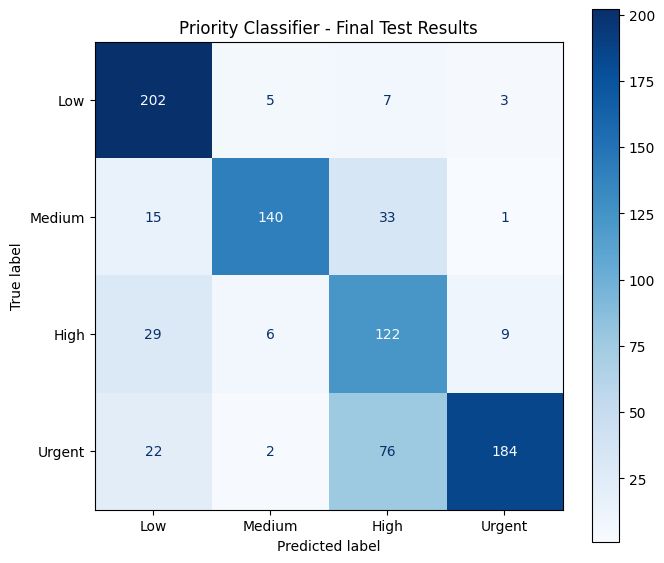


Saved:
E:\CitizenSense Sentiment Project\models\priority_classifier.joblib
E:\CitizenSense Sentiment Project\reports\priority_test_metrics.json
E:\CitizenSense Sentiment Project\reports\priority_test_predictions.csv
E:\CitizenSense Sentiment Project\reports\figures\priority_test_confusion_matrix.png


In [63]:

from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for folder in [MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Load the untouched test split
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

X_test = test_df["text"].astype(str)
y_test = test_df["priority"].astype(str)

# Final evaluation
test_predictions = priority_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)

priority_labels = ["Low", "Medium", "High", "Urgent"]

report = classification_report(
    y_test,
    test_predictions,
    labels=priority_labels,
    output_dict=True,
    zero_division=0
)

print(f"Priority Test Accuracy: {test_accuracy:.4f}")
print(f"Priority Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nFinal Test Classification Report:\n")
print(classification_report(
    y_test,
    test_predictions,
    labels=priority_labels,
    zero_division=0
))

# Save metrics
with open(REPORTS_DIR / "priority_test_metrics.json", "w") as f:
    json.dump({
        "accuracy": float(test_accuracy),
        "classification_report": report
    }, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=priority_labels
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=priority_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Priority Classifier - Final Test Results")
plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "priority_test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save individual test predictions
priority_results = test_df[
    ["id", "text", "priority"]
].copy()

priority_results["predicted_priority"] = test_predictions
priority_results["correct"] = (
    priority_results["priority"]
    == priority_results["predicted_priority"]
)

priority_results.to_csv(
    REPORTS_DIR / "priority_test_predictions.csv",
    index=False
)

# Save the trained model
joblib.dump(
    priority_model,
    MODELS_DIR / "priority_classifier.joblib"
)

print("\nSaved:")
print(MODELS_DIR / "priority_classifier.joblib")
print(REPORTS_DIR / "priority_test_metrics.json")
print(REPORTS_DIR / "priority_test_predictions.csv")
print(FIGURES_DIR / "priority_test_confusion_matrix.png")


Teeno models ki files check karo

In [64]:

from pathlib import Path

MODELS_DIR = Path(r"E:\CitizenSense Sentiment Project") / "models"

print("Model files currently available:\n")

if MODELS_DIR.exists():
    for path in sorted(MODELS_DIR.glob("*")):
        if path.is_file():
            print(path.name)
else:
    print("Models directory does not exist.")


Model files currently available:

priority_classifier.joblib
tfidf_logistic_regression.joblib
tfidf_sentiment_classifier.joblib


Teeno models ko aik prediction function mein combine karo

In [65]:

from pathlib import Path

MODELS_DIR = Path(r"E:\CitizenSense Sentiment Project\models")

print("Models folder exists:", MODELS_DIR.exists())
print("\nAvailable model files:")

for file in sorted(MODELS_DIR.glob("*")):
    if file.is_file():
        print(file.name)


Models folder exists: True

Available model files:
priority_classifier.joblib
tfidf_logistic_regression.joblib
tfidf_sentiment_classifier.joblib


In [66]:
from pathlib import Path
import joblib

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
MODELS_DIR = PROJECT_DIR / "models"

# Correct model file paths
CATEGORY_MODEL_FILE = MODELS_DIR / "tfidf_logistic_regression.joblib"
SENTIMENT_MODEL_FILE = MODELS_DIR / "tfidf_sentiment_classifier.joblib"
PRIORITY_MODEL_FILE = MODELS_DIR / "priority_classifier.joblib"

# Verify all model files exist
required_files = {
    "Category": CATEGORY_MODEL_FILE,
    "Sentiment": SENTIMENT_MODEL_FILE,
    "Priority": PRIORITY_MODEL_FILE
}

for name, path in required_files.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} model not found: {path}")

# Load all three trained models
category_model = joblib.load(CATEGORY_MODEL_FILE)
sentiment_model = joblib.load(SENTIMENT_MODEL_FILE)
priority_model = joblib.load(PRIORITY_MODEL_FILE)

print("All three models loaded successfully!")
print("Category model:", CATEGORY_MODEL_FILE.name)
print("Sentiment model:", SENTIMENT_MODEL_FILE.name)
print("Priority model:", PRIORITY_MODEL_FILE.name)

All three models loaded successfully!
Category model: tfidf_logistic_regression.joblib
Sentiment model: tfidf_sentiment_classifier.joblib
Priority model: priority_classifier.joblib


Imports and project paths

In [67]:
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())

Project directory: E:\CitizenSense Sentiment Project
Project directory exists: True


Load all three trained models

In [68]:
CATEGORY_MODEL_FILE = MODELS_DIR / "tfidf_logistic_regression.joblib"
SENTIMENT_MODEL_FILE = MODELS_DIR / "tfidf_sentiment_classifier.joblib"
PRIORITY_MODEL_FILE = MODELS_DIR / "priority_classifier.joblib"

required_files = {
    "Category": CATEGORY_MODEL_FILE,
    "Sentiment": SENTIMENT_MODEL_FILE,
    "Priority": PRIORITY_MODEL_FILE
}

for name, path in required_files.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} model not found: {path}")

category_model = joblib.load(CATEGORY_MODEL_FILE)
sentiment_model = joblib.load(SENTIMENT_MODEL_FILE)
priority_model = joblib.load(PRIORITY_MODEL_FILE)

print("All three models loaded successfully!")
print("Category:", CATEGORY_MODEL_FILE.name)
print("Sentiment:", SENTIMENT_MODEL_FILE.name)
print("Priority:", PRIORITY_MODEL_FILE.name)

All three models loaded successfully!
Category: tfidf_logistic_regression.joblib
Sentiment: tfidf_sentiment_classifier.joblib
Priority: priority_classifier.joblib


Load the processed datasets

In [69]:
TRAIN_FILE = PROCESSED_DIR / "train.csv"
VALIDATION_FILE = PROCESSED_DIR / "validation.csv"
TEST_FILE = PROCESSED_DIR / "test.csv"

for file in [TRAIN_FILE, VALIDATION_FILE, TEST_FILE]:
    if not file.exists():
        raise FileNotFoundError(f"Dataset file not found: {file}")

train_df = pd.read_csv(TRAIN_FILE)
validation_df = pd.read_csv(VALIDATION_FILE)
test_df = pd.read_csv(TEST_FILE)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

display(test_df.head())

Train shape: (4137, 10)
Validation shape: (1007, 10)
Test shape: (856, 10)


,id,text,category,sentiment,priority,source,label_method,group_id,text_length,word_count
0,18,kachra gari ka waqt kab hota hai?,Sanitation,Neutral,Low,seed_synthetic,hand_labeled,S_SN_20,33,7
1,22,"Hello sir, mujhe ye batana tha ke hamare mohalle mein sarak dhans gayi hai aur gaariyan us mein gir rahi hain. aap ki meherbani hogi.",Roads / Infrastructure,Friendly,Urgent,template_synthetic,rule_based,RD_U3,133,25
2,25,"nala saaf ho gaya hai, shukriya, hum sab is baat par ittefaq karte hain, pehle bhi is ka zikr kiya ja chuka hai.",Sanitation,Positive,Low,template_synthetic,rule_based,SN_R1,112,23
3,46,"block B mn pany ky motor chalane ke liye bijlee nahin hy, kis department ko batana chahiye?",Electricity,Neutral,High,template_synthetic,rule_based,EL_H10,91,17
4,61,"shukriya, line markings dobara ho gayi hain, mohalle ke baqi log bhi yehi keh rahe hain, yeh sab ek hi ilaqe ki baat hai",Roads / Infrastructure,Positive,Low,template_synthetic,rule_based,RD_R6,120,24


In [70]:
required_columns = {"text", "category", "sentiment", "priority"}

for split_name, df in {
    "train": train_df,
    "validation": validation_df,
    "test": test_df
}.items():
    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"{split_name} dataset is missing columns: {sorted(missing)}"
        )

    if df[list(required_columns)].isnull().any().any():
        print(f"Warning: missing values found in {split_name} data.")

print("\nCategory labels:")
print(sorted(train_df["category"].dropna().unique()))

print("\nSentiment labels:")
print(sorted(train_df["sentiment"].dropna().unique()))

print("\nPriority labels:")
print(sorted(train_df["priority"].dropna().unique()))

print("\nDataset verification completed.")


Category labels:
['Education', 'Electricity', 'Health', 'Roads / Infrastructure', 'Sanitation', 'Water Supply']

Sentiment labels:
['Friendly', 'Negative', 'Neutral', 'Positive']

Priority labels:
['High', 'Low', 'Medium', 'Urgent']

Dataset verification completed.


Create one function for all three predictions

In [71]:
def predict_complaint(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty complaint.")

    clean_text = text.strip()

    category = category_model.predict([clean_text])[0]
    sentiment = sentiment_model.predict([clean_text])[0]
    priority = priority_model.predict([clean_text])[0]

    result = {
        "Complaint": clean_text,
        "Predicted Category": category,
        "Predicted Sentiment": sentiment,
        "Predicted Priority": priority
    }

    models = {
        "Category": category_model,
        "Sentiment": sentiment_model,
        "Priority": priority_model
    }

    for name, model in models.items():
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba([clean_text])[0]
            result[f"{name} Confidence (%)"] = round(
                float(max(probabilities)) * 100, 2
            )

    return result

Test with one complaint

In [72]:
sample_complaint = (
    "Hamari gali mein kai dinon se pani nahi aa raha, "
    "barah-e-karam is maslay ko jald hal karein."
)

single_result = predict_complaint(sample_complaint)

display(pd.DataFrame([single_result]))

,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority,Category Confidence (%),Sentiment Confidence (%),Priority Confidence (%)
0,"Hamari gali mein kai dinon se pani nahi aa raha, barah-e-karam is maslay ko jald hal karein.",Water Supply,Negative,Medium,47.62,88.22,41.71


In [73]:
sample_complaints = [
    "Hamari gali mein pani nahi aa raha.",
    "Bijli kal raat se band hai aur ghar walay pareshan hain.",
    "Sarak par bohat gehre gadday hain, accident ka khatra hai.",
    "Kachra teen din se nahi uthaya gaya.",
    "Hospital mein emergency ke waqt doctor available nahi tha.",
    "School ki building ki chhat se pani tapak raha hai.",
    "Aap ki team ne hamari gali ka masla hal kar diya, bohat shukriya.",
    "Meherbani karke street light repair kar dein."
]

sample_results = pd.DataFrame(
    [predict_complaint(text) for text in sample_complaints]
)

display(sample_results)

sample_results.to_csv(
    REPORTS_DIR / "sample_complaint_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved sample predictions.")

,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority,Category Confidence (%),Sentiment Confidence (%),Priority Confidence (%)
0,Hamari gali mein pani nahi aa raha.,Water Supply,Negative,High,87.47,74.67,50.13
1,Bijli kal raat se band hai aur ghar walay pareshan hain.,Electricity,Negative,High,77.79,84.99,80.37
2,"Sarak par bohat gehre gadday hain, accident ka khatra hai.",Roads / Infrastructure,Negative,Urgent,90.85,66.60,40.48
3,Kachra teen din se nahi uthaya gaya.,Sanitation,Negative,Medium,59.06,69.24,70.25
4,Hospital mein emergency ke waqt doctor available nahi tha.,Health,Negative,Urgent,93.44,62.48,43.76
5,School ki building ki chhat se pani tapak raha hai.,Education,Negative,High,43.46,64.64,38.99
6,"Aap ki team ne hamari gali ka masla hal kar diya, bohat shukriya.",Roads / Infrastructure,Positive,Low,50.03,79.53,69.01
7,Meherbani karke street light repair kar dein.,Electricity,Friendly,Medium,83.37,43.29,48.58


Saved sample predictions.


Evaluate all models on the held-out test set

In [74]:
model_targets = {
    "Category": ("category", category_model),
    "Sentiment": ("sentiment", sentiment_model),
    "Priority": ("priority", priority_model)
}

evaluation_results = {}
test_predictions = test_df.copy()

for name, (target_column, model) in model_targets.items():
    y_true = test_df[target_column].astype(str)
    y_pred = model.predict(test_df["text"].fillna("").astype(str))

    accuracy = accuracy_score(y_true, y_pred)

    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    evaluation_results[name] = {
        "accuracy": round(float(accuracy), 4),
        "classification_report": report
    }

    test_predictions[f"{name.lower()}_actual"] = y_true.values
    test_predictions[f"{name.lower()}_predicted"] = y_pred

    print(f"\n{'=' * 55}")
    print(f"{name.upper()} MODEL")
    print(f"Accuracy: {accuracy:.2%}")
    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

with open(REPORTS_DIR / "integration_test_metrics.json", "w",
          encoding="utf-8") as f:
    json.dump(evaluation_results, f, indent=4, ensure_ascii=False)

test_predictions.to_csv(
    REPORTS_DIR / "integration_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved combined evaluation metrics and test predictions.")


CATEGORY MODEL
Accuracy: 85.86%
                        precision    recall  f1-score   support

             Education       0.90      0.93      0.91       195
           Electricity       0.84      0.85      0.84       120
                Health       0.86      0.98      0.92       142
Roads / Infrastructure       0.95      0.87      0.91       141
            Sanitation       0.92      0.69      0.79       129
          Water Supply       0.69      0.79      0.74       129

              accuracy                           0.86       856
             macro avg       0.86      0.85      0.85       856
          weighted avg       0.87      0.86      0.86       856


SENTIMENT MODEL
Accuracy: 98.25%
              precision    recall  f1-score   support

    Friendly       1.00      0.97      0.99       214
    Negative       0.95      1.00      0.97       225
     Neutral       1.00      0.97      0.98       205
    Positive       0.99      1.00      0.99       212

    accuracy      

In [75]:
error_frames = []

for name, (target_column, model) in model_targets.items():
    y_true = test_df[target_column].astype(str).reset_index(drop=True)
    y_pred = pd.Series(
        model.predict(test_df["text"].fillna("").astype(str)),
        name="predicted"
    )

    wrong_mask = y_true != y_pred

    if wrong_mask.any():
        errors = pd.DataFrame({
            "Task": name,
            "Text": test_df["text"].fillna("").astype(str).reset_index(drop=True),
            "Actual": y_true,
            "Predicted": y_pred
        })

        errors = errors.loc[wrong_mask].copy()
        error_frames.append(errors)

if error_frames:
    all_errors = pd.concat(error_frames, ignore_index=True)
else:
    all_errors = pd.DataFrame(
        columns=["Task", "Text", "Actual", "Predicted"]
    )

error_file = REPORTS_DIR / "error_analysis.csv"
all_errors.to_csv(error_file, index=False, encoding="utf-8-sig")

print("Total incorrect predictions across all three tasks:", len(all_errors))
print("Saved error analysis to:", error_file)

display(all_errors.head(25))

Total incorrect predictions across all three tasks: 344
Saved error analysis to: E:\CitizenSense Sentiment Project\reports\error_analysis.csv


,Task,Text,Actual,Predicted
0,Category,"nala saaf ho gaya hai, shukriya, hum sab is baat par ittefaq karte hain, pehle bhi is ka zikr kiya ja chuka hai.",Sanitation,Water Supply
1,Category,"shukriya, line markings dobara ho gayi hain, mohalle ke baqi log bhi yehi keh rahe hain, yeh sab ek hi ilaqe ki baat hai",Roads / Infrastructure,Sanitation
2,Category,"Line markings dobara ho gayi hain. sab ne bohat acha kaam kiya, hum khush hain, aas paas ke log bhi dekh rahe hain.",Roads / Infrastructure,Health
3,Category,"Respected sir, transformer se bohat tez awaaz aa rahi hai. aap ki madad ka intezar rahega, jazakAllah, aas paas ke log bhi dekh rahe hain, hum sab...",Electricity,Health
4,Category,"Kia aap bata sakte hain ke skool ki building mn aag lag gayi, to kis se rabta karun?",Education,Electricity
5,Category,"gali number 5 mein pani ki motor chalane ke liye bijli nahi hai, ye shikayat kahan darj karwani hai",Electricity,Water Supply
6,Category,"spray ho gaya he, acha kaam hua, par naaly ka ek hissa abhi bhi bnd he, baqi tafseel aap ke pas mojood he, mohalle ke baqi log bhi yehi keh rahe hn",Sanitation,Health
7,Category,"Shukriyah, spray ho gya hy, yeh ittila aap ko dena zaroori tha, baqi tafseel aap ke pas mojood he.",Sanitation,Health
8,Category,"pani ki motor chalane ke liye bijli nahi hai bazaar ke qareeb, aap ki meherbani hogi, is baray mein aap se rabta kiya hai, yeh ittila aap ko dena ...",Electricity,Water Supply
9,Category,"kitabein mil gyi hain, shukriya, mohalay ke baqi lug bhi yehi keh rahe hein, yeh ittila aap ko dena zaroori tha, baqi tafseel aap ke pas mojood hai",Education,Health


Keyword-based insights

In [76]:
KEYWORD_GROUPS = {
    "Water Supply": [
        "pani", "water", "tanker", "tanki", "supply"
    ],
    "Electricity": [
        "bijli", "electricity", "voltage", "light", "load shedding"
    ],
    "Roads / Infrastructure": [
        "sarak", "road", "gadday", "footpath", "bridge"
    ],
    "Sanitation": [
        "kachra", "kuda", "gandagi", "safai", "nala", "machar"
    ],
    "Health": [
        "hospital", "doctor", "dawai", "bimari", "emergency"
    ],
    "Education": [
        "school", "college", "teacher", "taleem", "class"
    ]
}


def extract_keyword_insights(text):
    text_lower = str(text).lower()
    matched_topics = []

    for topic, keywords in KEYWORD_GROUPS.items():
        matches = [
            keyword for keyword in keywords
            if keyword in text_lower
        ]

        if matches:
            matched_topics.append({
                "Topic": topic,
                "Matched Keywords": ", ".join(matches)
            })

    return matched_topics


def summarize_complaints(texts):
    topic_counts = {topic: 0 for topic in KEYWORD_GROUPS}

    for text in texts:
        matched = extract_keyword_insights(text)

        for item in matched:
            topic_counts[item["Topic"]] += 1

    summary = pd.DataFrame(
        [
            {"Topic": topic, "Complaint Count": count}
            for topic, count in topic_counts.items()
        ]
    )

    return summary.sort_values(
        "Complaint Count", ascending=False
    ).reset_index(drop=True)


keyword_summary = summarize_complaints(
    test_df["text"].fillna("").astype(str)
)

display(keyword_summary)

keyword_summary.to_csv(
    REPORTS_DIR / "keyword_insights.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved keyword insights.")

,Topic,Complaint Count
0,Water Supply,139
1,Education,120
2,Roads / Infrastructure,97
3,Sanitation,90
4,Electricity,86
5,Health,75


Saved keyword insights.


Interactive command-line demo

In [77]:
def predict_complaint(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty complaint.")

    text = text.strip()

    return {
        "Complaint": text,
        "Predicted Category": category_model.predict([text])[0],
        "Predicted Sentiment": sentiment_model.predict([text])[0],
        "Predicted Priority": priority_model.predict([text])[0]
    }


KEYWORD_GROUPS = {
    "Water Supply": ["pani", "water", "tanker", "tanki", "supply"],
    "Electricity": ["bijli", "electricity", "voltage", "light", "load shedding"],
    "Roads / Infrastructure": ["sarak", "road", "gadday", "footpath", "bridge"],
    "Sanitation": ["kachra", "kuda", "gandagi", "safai", "nala", "machar"],
    "Health": ["hospital", "doctor", "dawai", "bimari", "emergency"],
    "Education": ["school", "college", "teacher", "taleem", "class"]
}


def extract_keyword_insights(text):
    text = text.lower()
    insights = []

    for topic, keywords in KEYWORD_GROUPS.items():
        matched = [word for word in keywords if word in text]

        if matched:
            insights.append({
                "Topic": topic,
                "Matched Keywords": ", ".join(matched)
            })

    return insights


print("Prediction and keyword functions defined successfully.")

Prediction and keyword functions defined successfully.


In [78]:
from pathlib import Path
import joblib

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
MODELS_DIR = PROJECT_DIR / "models"

category_model = joblib.load(
    MODELS_DIR / "tfidf_logistic_regression.joblib"
)

sentiment_model = joblib.load(
    MODELS_DIR / "tfidf_sentiment_classifier.joblib"
)

priority_model = joblib.load(
    MODELS_DIR / "priority_classifier.joblib"
)

print("All three models loaded successfully!")

All three models loaded successfully!


In [79]:
test_complaint = "Hamari gali mein teen din se pani nahi aa raha."

print("Category:", category_model.predict([test_complaint])[0])
print("Sentiment:", sentiment_model.predict([test_complaint])[0])
print("Priority:", priority_model.predict([test_complaint])[0])

Category: Water Supply
Sentiment: Negative
Priority: High


In [80]:
from pathlib import Path
import joblib
import traceback

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
MODELS_DIR = PROJECT_DIR / "models"

try:
    print("Models folder exists:", MODELS_DIR.exists())
    print("Models folder:", MODELS_DIR)

    if not MODELS_DIR.exists():
        raise FileNotFoundError(
            f"Models folder not found: {MODELS_DIR}"
        )

    model_files = {
        "category_model": "tfidf_logistic_regression.joblib",
        "sentiment_model": "tfidf_sentiment_classifier.joblib",
        "priority_model": "priority_classifier.joblib"
    }

    loaded_models = {}

    for variable_name, filename in model_files.items():
        model_path = MODELS_DIR / filename

        if not model_path.exists():
            raise FileNotFoundError(
                f"Missing model file: {model_path}"
            )

        loaded_models[variable_name] = joblib.load(model_path)
        print(f"Loaded successfully: {filename}")

    # Assign variables only after all models load successfully
    category_model = loaded_models["category_model"]
    sentiment_model = loaded_models["sentiment_model"]
    priority_model = loaded_models["priority_model"]

    test_text = "Hamari gali mein teen din se pani nahi aa raha."

    print("\n--- Prediction Test ---")
    print("Category:", category_model.predict([test_text])[0])
    print("Sentiment:", sentiment_model.predict([test_text])[0])
    print("Priority:", priority_model.predict([test_text])[0])

    print("\nSUCCESS: All models loaded and predictions completed.")

except Exception:
    print("\nDIAGNOSTIC FAILED. Full error:")
    traceback.print_exc()

Models folder exists: True
Models folder: E:\CitizenSense Sentiment Project\models
Loaded successfully: tfidf_logistic_regression.joblib
Loaded successfully: tfidf_sentiment_classifier.joblib
Loaded successfully: priority_classifier.joblib

--- Prediction Test ---
Category: Water Supply
Sentiment: Negative
Priority: High

SUCCESS: All models loaded and predictions completed.


In [ ]:
from IPython.display import display
import pandas as pd

while True:
    complaint = input(
        "\nEnter a citizen complaint (or type 'exit' to stop): "
    ).strip()

    if complaint.lower() == "exit":
        print("CitizenSense demo ended.")
        break

    if not complaint:
        print("Please enter a complaint.")
        continue

    try:
        result = {
            "Complaint": complaint,
            "Predicted Category": category_model.predict([complaint])[0],
            "Predicted Sentiment": sentiment_model.predict([complaint])[0],
            "Predicted Priority": priority_model.predict([complaint])[0]
        }

        print("\n--- CITIZENSENSE ANALYSIS ---")
        display(pd.DataFrame([result]))

    except Exception as error:
        print("Prediction error:", error)


--- CITIZENSENSE ANALYSIS ---


,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority
0,mara rasta main bike sa accident ho gia hai,Health,Negative,Medium



--- CITIZENSENSE ANALYSIS ---


,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority
0,mara accident ho gia hai or main ab mrna wala hu,Electricity,Negative,Urgent



--- CITIZENSENSE ANALYSIS ---


...

,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority
0,mera female doctor pr dil agaya hay,Health,Negative,Urgent



--- CITIZENSENSE ANALYSIS ---


,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority
0,mujhay raat ko khwaab may pata chala ke meri gully may naya hospital khula hay,Health,Negative,High



--- CITIZENSENSE ANALYSIS ---


,Complaint,Predicted Category,Predicted Sentiment,Predicted Priority
0,"yaar aap khullay maay kiun moot rahay ho, mohallay may koora na phenko\",Education,Friendly,Low


In [ ]:
while True:
    complaint = input(
        "\nEnter a citizen complaint (or type 'exit' to stop): "
    ).strip()

    if complaint.lower() == "exit":
        print("Demo ended.")
        break

    if not complaint:
        print("Please enter a complaint.")
        continue

    try:
        result = predict_complaint(complaint)

        print("\n--- CITIZENSENSE PREDICTION ---")
        for key, value in result.items():
            print(f"{key}: {value}")

        matched_topics = extract_keyword_insights(complaint)

        print("\n--- KEYWORD INSIGHTS ---")
        if matched_topics:
            for item in matched_topics:
                print(f"- {item['Topic']}: {item['Matched Keywords']}")
        else:
            print("No configured keywords matched.")

    except Exception as error:
        print("Prediction error:", error)

Prediction error: name 'predict_complaint' is not defined


Create the Streamlit web application

In [ ]:
"""
CitizenSense - public feedback triage.
Loads the three models trained in CitizenSense.ipynb (category, sentiment, priority)
and shows a triage ticket for each complaint.

Run:  streamlit run citizensense_app.py
"""
from __future__ import annotations

import html
import os
import re
from pathlib import Path

import altair as alt
import joblib
import numpy as np
import pandas as pd
import streamlit as st

# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
APP_DIR = Path(__file__).resolve().parent

MODEL_FILES = {
    "category": "tfidf_logistic_regression.joblib",
    "sentiment": "tfidf_sentiment_classifier.joblib",
    "priority": "priority_classifier.joblib",
}

PRIORITIES = ["Low", "Medium", "High", "Urgent"]
PRI_COLOR = {"Low": "#4C7A9E", "Medium": "#B98A1F", "High": "#D0602A", "Urgent": "#B3261E"}
SENTIMENTS = ["Negative", "Neutral", "Positive", "Friendly"]
SENT_NOTE = {
    "Negative": "Complaint or frustration",
    "Neutral": "Question or status update",
    "Positive": "Thanks for a fix",
    "Friendly": "Polite, warm request",
}
SENT_TONE = {
    "Negative": "A complaint",
    "Neutral": "A question or status update",
    "Positive": "Appreciation",
    "Friendly": "A polite request",
}

DEPARTMENTS = {
    "Roads / Infrastructure": "Roads and highways department",
    "Water Supply": "Water and sanitation authority",
    "Electricity": "Power distribution company",
    "Sanitation": "Municipal waste management",
    "Health": "Health department and district hospital",
    "Education": "School education department",
}
ISSUE_WORD = {
    "Roads / Infrastructure": "roads",
    "Water Supply": "water supply",
    "Electricity": "electricity",
    "Sanitation": "sanitation",
    "Health": "health services",
    "Education": "education",
}
ACTIONS = {
    "Urgent": "Send a response team now and alert the duty officer.",
    "High": "Assign to a field team within 24 hours.",
    "Medium": "Schedule a fix this week and update the citizen.",
    "Low": "Log it and handle in the routine queue.",
}

EXAMPLES = [
    "Hamari gali mein 3 din se pani nahi aa raha, bohat pareshani hai.",
    "Mere walid ko dil ka daura para hai aur ambulance nahi aa rahi.",
    "Bijli ki taar sarak par gir gayi hai aur chingariyan nikal rahi hain.",
    "Assalam o Alaikum, street light kharab hai, aap ki meherbani hogi agar theek ho jaye.",
    "School ki chat tapakti hai aur kitabein bheeg jati hain.",
    "Shukriya, nala saaf ho gaya hai.",
]

# Words that signal danger to life. Used by the optional safety rule.
DANGER_TERMS = [
    "maut", "faut", "intiqal", "inteqal", "jaan chali", "jaan ka khatra", "mar gaya", "mar gayi",
    "mar gaye", "dum tod", "behosh", "dil ka daura", "heart attack", "stroke", "saanp ne", "zehar",
    "zakhmi", "khoon beh", "shadeed khoon", "aag lag", "karant lag", "karant aa", "jhatka lag",
    "doob gaya", "doob gayi", "oxygen khatam", "ambulance nahi", "chingari",
    "died", "death", "dead", "electrocut", "unconscious", "bleeding", "on fire",
]

STOP = set("""
hai hain ka ki ke ko se mein main par aur ne bhi to ho tha thi the raha rahi rahe gaya gayi gaye kar karein
kya nahi nhi is iska yeh ye wo woh hum hamare hamari hamara aap ap ek koi bohat bahut bohot kai jaldi
the of and in for sir janab salam assalam alaikum shukriya meherbani hogi dein do diya di liye ab abhi tak
sirf jab jo kuch ya please aaj kal subah raat din
""".split())

# ----------------------------------------------------------------------------
# Page + styling
# ----------------------------------------------------------------------------
st.set_page_config(page_title="CitizenSense", page_icon="🏛️", layout="wide")

CSS = """
<style>
@import url('https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:opsz,wght@12..96,500;12..96,700&family=Public+Sans:wght@400;500;600&display=swap');
:root{--paper:#F3F5F7;--surface:#FFFFFF;--ink:#15222E;--muted:#5B6B7A;--line:#D9E0E6;--navy:#16365C;}
html, body, .stApp, [class*="css"]{font-family:'Public Sans',system-ui,-apple-system,'Segoe UI',sans-serif;color:var(--ink);}
.stApp{background:var(--paper);}
#MainMenu, footer{visibility:hidden;}
header[data-testid="stHeader"]{background:transparent;}
.block-container{padding-top:2rem;max-width:1180px;}
.masthead h1{font-family:'Bricolage Grotesque',system-ui,sans-serif;font-size:2.7rem;font-weight:700;letter-spacing:-0.02em;margin:0;color:var(--navy);}
.masthead p{color:var(--muted);font-size:1.05rem;margin:.4rem 0 0;max-width:58ch;line-height:1.5;}
.rail{display:flex;height:6px;margin:1.1rem 0 1.5rem;border-radius:3px;overflow:hidden;max-width:240px;}
.rail span{flex:1;}
.ticket{background:var(--surface);border:1px solid var(--line);border-radius:8px;overflow:hidden;}
.band{padding:1.15rem 1.4rem 1.2rem;color:#fff;}
.band .small{font-size:.85rem;opacity:.92;}
.band .big{font-family:'Bricolage Grotesque',system-ui,sans-serif;font-size:3.1rem;font-weight:700;line-height:1.05;letter-spacing:-0.01em;}
.band .act{margin-top:.55rem;font-size:1.02rem;line-height:1.4;}
.band .note{margin-top:.6rem;font-size:.88rem;background:rgba(255,255,255,.16);padding:.4rem .6rem;border-radius:5px;}
.row3{display:grid;grid-template-columns:repeat(3,1fr);border-bottom:1px solid var(--line);}
.cell{padding:.95rem 1.2rem;border-right:1px solid var(--line);}
.cell:last-child{border-right:0;}
.cell .k{font-size:.8rem;color:var(--muted);}
.cell .v{font-family:'Bricolage Grotesque',system-ui,sans-serif;font-size:1.3rem;font-weight:600;line-height:1.25;margin:.15rem 0;}
.cell .n{font-size:.84rem;color:var(--muted);}
.sec{padding:.95rem 1.4rem;border-bottom:1px solid var(--line);}
.sec:last-child{border-bottom:0;}
.sec h4{font-size:.86rem;font-weight:600;color:var(--muted);margin:0 0 .55rem;}
.sec p{margin:0;line-height:1.5;}
.chip{display:inline-block;padding:.18rem .65rem;margin:0 .35rem .35rem 0;border:1px solid var(--line);border-radius:999px;background:#F7F9FA;font-size:.92rem;}
.bar-row{display:grid;grid-template-columns:78px 1fr 44px;gap:.7rem;align-items:center;font-size:.88rem;margin:.28rem 0;}
.bar{height:8px;background:#E8EDF1;border-radius:4px;overflow:hidden;}
.bar i{display:block;height:100%;}
.pct{text-align:right;color:var(--muted);font-variant-numeric:tabular-nums;}
.review{display:inline-block;margin:0 0 .9rem;padding:.45rem .75rem;border-left:4px solid #B98A1F;background:#FBF4E3;border-radius:0 5px 5px 0;font-size:.92rem;}
.empty{border:1px dashed #BFCAD3;border-radius:8px;padding:2.2rem 1.6rem;color:var(--muted);line-height:1.55;background:rgba(255,255,255,.5);}
.empty b{color:var(--ink);}
.stTextArea textarea{border-radius:8px;border:1px solid var(--line);background:#fff;font-size:1rem;line-height:1.5;}
.stButton>button{border-radius:6px;font-weight:600;border:1px solid var(--line);}
.stButton>button, .stButton>button p{color:var(--ink);}
.stButton>button:not([kind="primary"]):not([data-testid="stBaseButton-primary"]){background:var(--surface);border:1px solid var(--line);text-align:left;justify-content:flex-start;}
.stButton>button:not([kind="primary"]):not([data-testid="stBaseButton-primary"]):hover{background:#EAF0F5;border-color:var(--navy);color:var(--navy);}
.stButton>button:not([kind="primary"]):not([data-testid="stBaseButton-primary"]):hover p{color:var(--navy);}
.stButton>button[kind="primary"] p, .stButton>button[data-testid="stBaseButton-primary"] p{color:#fff;}
.stButton>button[kind="primary"], .stButton>button[data-testid="stBaseButton-primary"]{background:var(--navy);border-color:var(--navy);color:#fff;}
.stTabs [data-baseweb="tab-list"]{gap:.4rem;}
.stTabs [data-baseweb="tab"]{font-weight:600;}
@media (max-width:640px){
  .masthead h1{font-size:2.1rem;}
  .row3{grid-template-columns:1fr;}
  .cell{border-right:0;border-bottom:1px solid var(--line);}
  .band .big{font-size:2.5rem;}
}
</style>
"""
st.markdown(CSS, unsafe_allow_html=True)

RAIL = "".join(f'<span style="background:{PRI_COLOR[p]}"></span>' for p in PRIORITIES)
st.markdown(
    f'<div class="masthead"><h1>CitizenSense</h1>'
    f'<p>Paste a citizen complaint. See what it is about, how the citizen feels, '
    f'how urgent it is, and which office should handle it.</p></div>'
    f'<div class="rail">{RAIL}</div>',
    unsafe_allow_html=True,
)

# ----------------------------------------------------------------------------
# Models
# ----------------------------------------------------------------------------
def default_model_dir() -> str:
    candidates = [os.environ.get("CITIZENSENSE_MODELS"), APP_DIR / "models",
                  r"E:\CitizenSense Sentiment Project\models"]
    for c in candidates:
        if c and all((Path(c) / f).exists() for f in MODEL_FILES.values()):
            return str(c)
    return str(APP_DIR / "models")


@st.cache_resource(show_spinner=False)
def load_models(folder: str):
    d = Path(folder)
    missing = [f for f in MODEL_FILES.values() if not (d / f).exists()]
    if missing:
        raise FileNotFoundError("Missing: " + ", ".join(missing))
    return {task: joblib.load(d / name) for task, name in MODEL_FILES.items()}


with st.sidebar:
    st.markdown("### Settings")
    model_dir = st.text_input("Models folder", value=default_model_dir())
    use_safety = st.toggle(
        "Escalate danger to life",
        value=True,
        help="If a complaint mentions death, injury, fire, electric shock or a medical emergency, "
             "raise its priority to Urgent even if the model scored it lower.",
    )
    review_below = st.slider(
        "Ask for human review below", 0.30, 0.90, 0.50, 0.05,
        help="If any model is less sure than this, the ticket is flagged for a person to check.",
    )
    st.caption("Predictions are suggestions to help staff sort complaints. A person makes the final call.")

try:
    MODELS = load_models(model_dir)
except Exception as err:  # noqa: BLE001
    st.error(
        f"Could not load the models from `{model_dir}`. {err}\n\n"
        "Run the training cells in CitizenSense.ipynb so the three .joblib files exist, "
        "then point **Models folder** (left sidebar) to that folder."
    )
    st.stop()

with st.sidebar:
    st.success("Three models loaded")

# ----------------------------------------------------------------------------
# Prediction helpers
# ----------------------------------------------------------------------------
def danger_hit(text: str) -> str | None:
    t = text.lower()
    for term in DANGER_TERMS:
        if term in t:
            return term
    return None


def top_terms(pipe, text: str, label: str, n: int = 8) -> list[str]:
    """Words in this text that pushed the model toward `label`."""
    try:
        tfidf = pipe.named_steps["tfidf"]
        clf = pipe.named_steps["classifier"]
        x = tfidf.transform([text]).tocoo()
        names = tfidf.get_feature_names_out()
        k = list(clf.classes_).index(label)
        coef = clf.coef_[k]
        scored = [(names[j], v * coef[j]) for j, v in zip(x.col, x.data) if v * coef[j] > 0]
        scored.sort(key=lambda s: -s[1])
        return [w for w, _ in scored[:n]]
    except Exception:  # noqa: BLE001
        return []


def pick_keywords(text: str, cat_label: str, pri_label: str, limit: int = 6) -> list[str]:
    candidates = top_terms(MODELS["category"], text, cat_label) + top_terms(MODELS["priority"], text, pri_label)
    out: list[str] = []
    for term in candidates:
        tokens = term.split()
        if all(tok in STOP or len(tok) < 3 for tok in tokens):
            continue
        if any(term in o or o in term for o in out):
            continue
        out.append(term)
        if len(out) == limit:
            break
    if not out:
        out = [w for w in re.findall(r"[A-Za-z']{3,}", text.lower()) if w not in STOP][:5]
    return out


def predict_one(text: str) -> dict:
    result: dict = {}
    for task in ("category", "sentiment", "priority"):
        model = MODELS[task]
        proba = model.predict_proba([text])[0]
        classes = list(model.classes_)
        i = int(np.argmax(proba))
        result[task] = {"label": classes[i], "conf": float(proba[i]), "dist": dict(zip(classes, map(float, proba)))}

    model_priority = result["priority"]["label"]
    final_priority, escalated_by = model_priority, None
    if use_safety:
        term = danger_hit(text)
        if term and PRIORITIES.index(model_priority) < PRIORITIES.index("Urgent"):
            final_priority, escalated_by = "Urgent", term
    keywords = pick_keywords(text, result["category"]["label"], model_priority)
    kw_text = ", ".join(keywords[:3]) if keywords else "no clear keywords"
    summary = (
        f"{SENT_TONE[result['sentiment']['label']]} about {ISSUE_WORD.get(result['category']['label'], 'a public service')}. "
        f"Main points: {kw_text}. Suggested priority: {final_priority.lower()}."
    )
    min_conf = min(result[t]["conf"] for t in ("category", "sentiment", "priority"))
    return {
        "text": text,
        "category": result["category"],
        "sentiment": result["sentiment"],
        "priority": result["priority"],
        "final_priority": final_priority,
        "model_priority": model_priority,
        "escalated_by": escalated_by,
        "keywords": keywords,
        "department": DEPARTMENTS.get(result["category"]["label"], "Relevant department"),
        "action": ACTIONS[final_priority],
        "summary": summary,
        "needs_review": min_conf < review_below,
        "min_conf": min_conf,
    }


def predict_many(texts: list[str]) -> pd.DataFrame:
    frame = pd.DataFrame({"text": texts})
    for task in ("category", "sentiment", "priority"):
        model = MODELS[task]
        proba = model.predict_proba(texts)
        classes = np.array(model.classes_)
        frame[task] = classes[proba.argmax(axis=1)]
        frame[f"{task}_confidence"] = proba.max(axis=1).round(3)
    frame["model_priority"] = frame["priority"]
    frame["escalated_by"] = ""
    if use_safety:
        for i, t in enumerate(texts):
            term = danger_hit(t)
            if term and frame.at[i, "priority"] != "Urgent":
                frame.at[i, "priority"] = "Urgent"
                frame.at[i, "escalated_by"] = term
    frame["department"] = frame["category"].map(DEPARTMENTS)
    frame["suggested_action"] = frame["priority"].map(ACTIONS)
    frame["needs_review"] = frame[["category_confidence", "sentiment_confidence", "priority_confidence"]].min(axis=1) < review_below
    return frame


# ----------------------------------------------------------------------------
# Rendering helpers
# ----------------------------------------------------------------------------
def esc(x) -> str:
    return html.escape(str(x))


def bars(dist: dict, order: list[str], color_of) -> str:
    rows = []
    for label in order:
        p = dist.get(label, 0.0)
        rows.append(
            f'<div class="bar-row"><span>{esc(label)}</span>'
            f'<div class="bar"><i style="width:{p*100:.0f}%;background:{color_of(label)}"></i></div>'
            f'<span class="pct">{p*100:.0f}%</span></div>'
        )
    return "".join(rows)


def render_ticket(r: dict) -> str:
    color = PRI_COLOR[r["final_priority"]]
    note = ""
    if r["escalated_by"]:
        note = (f'<div class="note">The model scored this {esc(r["model_priority"])}. '
                f'Raised to Urgent because the text mentions "{esc(r["escalated_by"])}".</div>')
    review = ""
    if r["needs_review"]:
        review = ('<div class="review">The models are not very sure about this one '
                  f'(lowest confidence {r["min_conf"]*100:.0f}%). Please have a person check it.</div>')
    chips = "".join(f'<span class="chip">{esc(k)}</span>' for k in r["keywords"]) or "<span>No clear keywords found.</span>"
    s_label = r["sentiment"]["label"]
    return (
        review
        + '<div class="ticket">'
        + f'<div class="band" style="background:{color}"><div class="small">Priority</div>'
        + f'<div class="big">{esc(r["final_priority"])}</div>'
        + f'<div class="act">{esc(r["action"])}</div>{note}</div>'
        + '<div class="row3">'
        + f'<div class="cell"><div class="k">Topic</div><div class="v">{esc(r["category"]["label"])}</div>'
        + f'<div class="n">{r["category"]["conf"]*100:.0f}% sure</div></div>'
        + f'<div class="cell"><div class="k">Tone</div><div class="v">{esc(s_label)}</div>'
        + f'<div class="n">{esc(SENT_NOTE.get(s_label, ""))} ({r["sentiment"]["conf"]*100:.0f}% sure)</div></div>'
        + f'<div class="cell"><div class="k">Send to</div><div class="v">{esc(r["department"])}</div>'
        + '<div class="n">Suggested office</div></div></div>'
        + f'<div class="sec"><h4>Summary</h4><p>{esc(r["summary"])}</p></div>'
        + f'<div class="sec"><h4>Words that shaped the result</h4>{chips}</div>'
        + '<div class="sec"><h4>How sure the priority model is</h4>'
        + bars(r["priority"]["dist"], PRIORITIES, lambda l: PRI_COLOR[l])
        + '</div></div>'
    )


def count_chart(series: pd.Series, order: list[str], colors: dict | None = None):
    counts = series.value_counts().reindex(order, fill_value=0).rename_axis("label").reset_index(name="count")
    palette = [colors[o] for o in order] if colors else ["#16365C"] * len(order)
    return (
        alt.Chart(counts)
        .mark_bar(cornerRadiusEnd=3)
        .encode(
            x=alt.X("count:Q", title=None),
            y=alt.Y("label:N", sort=order, title=None),
            color=alt.Color("label:N", scale=alt.Scale(domain=order, range=palette), legend=None),
            tooltip=["label", "count"],
        )
        .properties(height=34 * len(order) + 16, width="container")
        .configure_view(strokeWidth=0)
        .configure_axis(grid=False, labelFont="Public Sans", labelFontSize=13, domain=False)
    )


def show_charts(frame: pd.DataFrame):
    c1, c2, c3 = st.columns(3, gap="large")
    with c1:
        st.markdown("**Priority**")
        st.altair_chart(count_chart(frame["priority"], PRIORITIES, PRI_COLOR))
    with c2:
        st.markdown("**Topic**")
        st.altair_chart(count_chart(frame["category"], sorted(DEPARTMENTS)))
    with c3:
        st.markdown("**Tone**")
        st.altair_chart(count_chart(frame["sentiment"], SENTIMENTS))


# ----------------------------------------------------------------------------
# State
# ----------------------------------------------------------------------------
st.session_state.setdefault("complaint", "")
st.session_state.setdefault("history", [])
st.session_state.setdefault("last", None)


def use_example(text: str):
    st.session_state["complaint"] = text


tab_one, tab_file, tab_insights, tab_about = st.tabs(
    ["Analyze a complaint", "Analyze a file", "Session insights", "How it works"]
)

# ----------------------------------------------------------------------------
# Tab: single complaint
# ----------------------------------------------------------------------------
with tab_one:
    left, right = st.columns([5, 7], gap="large")
    with left:
        st.text_area(
            "Complaint text",
            key="complaint",
            height=180,
            placeholder="Write or paste a complaint in Roman Urdu or English",
        )
        analyze = st.button("Analyze complaint", type="primary")
        st.markdown("<div style='height:.6rem'></div>", unsafe_allow_html=True)
        st.caption("Or start from an example")
        for i, ex in enumerate(EXAMPLES):
            st.button(ex, key=f"ex{i}", on_click=use_example, args=(ex,))

    if analyze:
        text = st.session_state["complaint"].strip()
        if not text:
            st.session_state["last"] = None
            with left:
                st.warning("Type a complaint first, then select Analyze complaint.")
        else:
            res = predict_one(text)
            st.session_state["last"] = res
            st.session_state["history"].append(
                {
                    "complaint": text,
                    "topic": res["category"]["label"],
                    "tone": res["sentiment"]["label"],
                    "priority": res["final_priority"],
                    "send_to": res["department"],
                    "needs_review": res["needs_review"],
                }
            )

    with right:
        if st.session_state["last"]:
            st.markdown(render_ticket(st.session_state["last"]), unsafe_allow_html=True)
        else:
            st.markdown(
                '<div class="empty"><b>Nothing analyzed yet.</b><br>'
                'Write a complaint on the left, or pick an example, and select <b>Analyze complaint</b>. '
                'The ticket for it will appear here.</div>',
                unsafe_allow_html=True,
            )

# ----------------------------------------------------------------------------
# Tab: file
# ----------------------------------------------------------------------------
with tab_file:
    st.markdown("Upload a CSV with one complaint per row. CitizenSense will label every row and let you download the result.")
    up = st.file_uploader("CSV file", type=["csv"], label_visibility="collapsed")
    if up is None:
        st.markdown(
            '<div class="empty"><b>No file yet.</b><br>Choose a CSV that has a column of complaint text.</div>',
            unsafe_allow_html=True,
        )
    else:
        try:
            raw = pd.read_csv(up)
        except Exception as err:  # noqa: BLE001
            st.error(f"That file could not be read as a CSV: {err}")
            raw = None
        if raw is not None:
            if raw.empty:
                st.warning("The file has no rows.")
            else:
                text_cols = [c for c in raw.columns if raw[c].dtype == object]
                if not text_cols:
                    st.error("No text column found. The file needs at least one column of complaint text.")
                else:
                    default_i = text_cols.index("text") if "text" in text_cols else 0
                    col = st.selectbox("Which column has the complaint text?", text_cols, index=default_i)
                    st.caption(f"{len(raw):,} rows in the file")
                    if st.button("Analyze all rows", type="primary"):
                        texts = raw[col].fillna("").astype(str).str.strip().tolist()
                        with st.spinner("Reading complaints"):
                            out = predict_many(texts)
                        extra = raw.drop(columns=[col]).reset_index(drop=True)
                        st.session_state["batch"] = pd.concat([out, extra], axis=1)
                    batch = st.session_state.get("batch")
                    if batch is not None and len(batch) == len(raw):
                        st.markdown(
                            f"**{len(batch):,} complaints labeled.** "
                            f"{int((batch['priority'] == 'Urgent').sum()):,} urgent, "
                            f"{int(batch['needs_review'].sum()):,} flagged for human review."
                        )
                        show_charts(batch)
                        st.dataframe(batch)
                        st.download_button(
                            "Download labeled CSV",
                            data=batch.to_csv(index=False).encode("utf-8-sig"),
                            file_name="citizensense_labeled.csv",
                            mime="text/csv",
                        )

# ----------------------------------------------------------------------------
# Tab: insights
# ----------------------------------------------------------------------------
with tab_insights:
    hist = pd.DataFrame(st.session_state["history"])
    if hist.empty:
        st.markdown(
            '<div class="empty"><b>No complaints analyzed in this session.</b><br>'
            'Analyze a few on the first tab and the totals will show up here.</div>',
            unsafe_allow_html=True,
        )
    else:
        n_urgent = int((hist["priority"] == "Urgent").sum())
        st.markdown(f"**{len(hist)} complaints this session.** {n_urgent} urgent, {int(hist['needs_review'].sum())} flagged for review.")
        show_charts(hist.rename(columns={"topic": "category", "tone": "sentiment"}))
        st.dataframe(hist)
        st.download_button(
            "Download session history",
            data=hist.to_csv(index=False).encode("utf-8-sig"),
            file_name="citizensense_session.csv",
            mime="text/csv",
        )
        if st.button("Clear history"):
            st.session_state["history"] = []
            st.session_state["last"] = None
            st.rerun()

# ----------------------------------------------------------------------------
# Tab: how it works
# ----------------------------------------------------------------------------
with tab_about:
    st.markdown(
        """
**What happens to a complaint**

Three small text models read the same complaint. One picks the topic, one reads the tone, and one scores the priority.
Each model turns the words into numbers (TF-IDF) and then makes a choice with logistic regression.
The words that pushed the result most are shown as chips on the ticket.

**What the labels mean**

- **Urgent:** danger to life or safety, such as a death, an injury, an electric shock, a fire, a collapse, or a life-threatening illness.
- **High:** a serious problem, such as an essential service down for days, a serious illness, or a risk to children.
- **Medium:** an ongoing inconvenience, such as a billing dispute or a non-serious illness.
- **Low:** a small problem or a question for information.
- **Friendly** means the writer is warm and polite (greeting, courtesy). **Positive** means the writer is thanking staff for a fix.

**Escalate danger to life**

When this is on (left sidebar), any complaint that mentions death, injury, fire, electric shock or a medical emergency is raised to Urgent,
and the ticket says why. This is a plain word list, so it is a safety net and not a replacement for the model.

**Limits**

- The models learned from synthetic Roman Urdu complaints, so real messages with unusual spelling or mixed topics can be wrong.
- Complaints that mention two topics (for example water in a hospital) can be filed under the wrong one.
- Every result is a suggestion. A person should confirm Urgent and flagged tickets.
"""
    )


NameError: name 'PROJECT_DIR' is not defined

Check that all expected outputs exist

In [ ]:
expected_outputs = [
    REPORTS_DIR / "integration_test_metrics.json",
    REPORTS_DIR / "integration_test_predictions.csv",
    REPORTS_DIR / "error_analysis.csv",
    REPORTS_DIR / "20_sample_predictions.csv",
    REPORTS_DIR / "keyword_insights.csv",
    REPORTS_DIR / "predicted_priority_distribution.csv",
    APP_FILE
]

print("Output verification:\n")

for path in expected_outputs:
    print(f"{'OK' if path.exists() else 'MISSING'} — {path.name}")

In [1]:
import pandas as pd
from IPython.display import display, Markdown

def run_citizensense_demo():
    print("=" * 60)
    print("       CITIZENSENSE — CITIZEN FEEDBACK ANALYZER")
    print("=" * 60)

    complaint = input("\nEnter citizen complaint: ").strip()

    if not complaint:
        print("Please enter a valid complaint.")
        return

    # Predict using the three loaded models
    category = category_model.predict([complaint])[0]
    sentiment = sentiment_model.predict([complaint])[0]
    priority = priority_model.predict([complaint])[0]

    # Display results
    display(Markdown("## Analysis Results"))

    results = [
        {"Output": "Complaint", "Prediction": complaint},
        {"Output": "Category", "Prediction": category},
        {"Output": "Sentiment", "Prediction": sentiment},
        {"Output": "Priority", "Prediction": priority}
    ]

    display(pd.DataFrame(results))

    # Display confidence when supported by the model
    models

In [2]:
import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path(r"E:\CitizenSense Sentiment Project")
APP_FILE = PROJECT_DIR / "citizensense_app.py"

if not APP_FILE.exists():
    raise FileNotFoundError(f"App not found: {APP_FILE}")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(APP_FILE),
        "--server.port", "8501"
    ],
    cwd=str(PROJECT_DIR)
)

print("CitizenSense is starting...")
print("Open your browser at: http://localhost:8501")
print("Streamlit process ID:", process.pid)

CitizenSense is starting...
Open your browser at: http://localhost:8501
Streamlit process ID: 19164
